# Week 3 — Predictive Modeling on Encoded Text

**ISM 6564 — Text Analytics · Fall 2026 · lecture notebook**

Week 2 turned documents into vectors. This week we put a label on the other
end and ask the models you already own from ISM 6251 to predict it.

You know how logistic regression, kNN, SVC, random forests, XGBoost and a
feedforward ANN work. **This notebook is not about the algorithms.** It is
about what changes when the feature matrix is 2,257 × 12,959 and 99.5% zero:
which of those models still work, which quietly fall over, and how to tell the
difference without lying to yourself.

Every number below is computed in the cell above it. Nothing is quoted from
memory, and the results that are unflattering are left in.

| § | Block | What we actually do |
|---|---|---|
| 0 | Setup | Seeds, device, corpus |
| 1 | The supervised text pipeline | Leakage, measured twice — once catastrophic, once negligible; `Pipeline` as the fix; stratification |
| 2 | Linear and instance-based | Logistic regression as the baseline to beat; coefficients as features; `LinearSVC` has no `predict_proba`; cosine-kNN vs Euclidean-kNN, and a result we cannot explain yet |
| 3 | Trees and ensembles | Random forest and XGBoost lose to a linear model on sparse text — and exactly why; SVD as the fix |
| 4 | Feedforward ANN | `MLPClassifier` on TF-IDF; the same MLP in PyTorch; then §4.4 — the whole road on the ticket corpus — and §4.5, the slide deck&rsquo;s ticket-model numbers, reproduced |
| 5 | Evaluation, honestly | macro vs micro vs weighted; the confusion matrix; can you trust `predict_proba`; **error analysis, where §2's unexplained result gets its answer** |
| 6 | Model selection | Grid search over a `Pipeline`; the ceiling of bag-of-words |
| 7 | Carry forward | What breaks, and what Week 4 does about it |

**Prerequisite:** `pytorch-primer.ipynb` in this folder. §4.3 and §4.4 assume it.

A few sections go past what class covers: §4.2 *(preview of Week 4)*,
§5.6 and §6.2 *(reference)* are marked at their headers, and §5.4's ROC
portion is likewise reference. Read them when you need them; nothing in the
quiz or the assignment depends on them.

**No API key is needed anywhere in this notebook.**

## 0 — Setup

### 0.1 Imports, seeds, device

Read the first four lines before you run this. This notebook is the first one
in the course that loads **both PyTorch and XGBoost into the same process**,
and on macOS that combination segfaults: each library ships its own copy of the
OpenMP runtime, two OpenMP runtimes in one process is undefined behaviour, and
what you get is a dead kernel with no traceback part-way through §3.

Pinning `OMP_NUM_THREADS=1` **before either import** avoids it. It has to be
set before, because the runtime reads it at load time. XGBoost gets slower —
about 20 seconds instead of 10 on this corpus — which is the price.

This is not course trivia. It is a representative example of the failure mode
that eats an afternoon: no exception, no error message, no stack trace, and a
cause that has nothing to do with your code.

In [1]:
import os
import sys

# MUST come before importing torch or xgboost -- see the note above.
if sys.platform == "darwin":
    os.environ["OMP_NUM_THREADS"] = "1"

import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import sklearn
import xgboost as xgb
import torch

# --- reproducibility: every source of randomness in this notebook ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- portable device block -------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(f"numpy    {np.__version__}")
print(f"sklearn  {sklearn.__version__}")
print(f"xgboost  {xgb.__version__}")
print(f"torch    {torch.__version__}  ->  device: {device}")
print(f"platform {sys.platform}   OMP_NUM_THREADS={os.environ.get('OMP_NUM_THREADS', 'unset')}")

numpy    2.4.4
sklearn  1.8.0
xgboost  3.4.1
torch    2.11.0  ->  device: mps
platform darwin   OMP_NUM_THREADS=1


`torch` is here for §4.3, where we rebuild the sklearn `MLPClassifier` of §4.1
by hand. That is not a gratuitous detour: it is the last model in the course
you can specify completely in one screen of code, and Week 4's recurrent
network is the same training loop with a different `forward`.

### 0.2 Plot styling

One place to set chart defaults, matching Week 2, so every figure across the
course reads as the same system: a fixed categorical colour order assigned by
slot (never cycled arbitrarily), a recessive grid, no chart junk.

In [2]:
# Fixed categorical order — colours are assigned by slot, never recycled.
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]
INK, INK_2, GRIDC = "#0b0b0b", "#52514e", "#dcdbd6"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRIDC,
    "axes.labelcolor": INK_2,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.grid": True,
    "grid.color": GRIDC,
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "font.size": 9,
    "legend.frameon": False,
})
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 90)
np.set_printoptions(precision=4, suppress=True, linewidth=150)
warnings.filterwarnings("ignore", category=UserWarning)
print("plot defaults set")

plot defaults set


### 0.3 The corpus

**20 Newsgroups**, four groups, fetched by `sklearn.datasets` — *not* vendored
in `data/`. It downloads once to `~/scikit_learn_data/` and is cached after
that, so there is nothing to check into the repository.

Two choices in that call matter and are not cosmetic:

- `remove=("headers", "footers", "quotes")` strips the `From:`, `Organization:`
  and signature lines. Leave them in and a classifier learns *"this post came
  from a `.nasa.gov` address"* — accuracy in the high nineties and a model that
  has learned nothing about text. This is the single most common way the 20
  Newsgroups benchmark gets reported dishonestly.
- The four groups are picked so the task is not trivial. `comp.graphics` and
  `sci.med` are cleanly separated from everything; **`alt.atheism` and
  `soc.religion.christian` are the notoriously confusable pair** — same subject
  matter, opposite position — and `alt.atheism` is also the smallest group.
  That pair is what makes §5.2's macro-vs-micro argument and §5.8's error
  analysis worth doing.

20 Newsgroups also ships its own train/test split, made **by date** — the test
posts were written after the training posts. That is a more honest split than a
random one, and we keep it. The official test set is our held-out set and is
not touched until §2.

In [3]:
from sklearn.datasets import fetch_20newsgroups

CATS = ["alt.atheism", "comp.graphics", "sci.med", "soc.religion.christian"]

train_raw = fetch_20newsgroups(subset="train", categories=CATS,
                               remove=("headers", "footers", "quotes"),
                               shuffle=True, random_state=SEED)
test_raw = fetch_20newsgroups(subset="test", categories=CATS,
                              remove=("headers", "footers", "quotes"),
                              shuffle=True, random_state=SEED)

docs_tr, y_tr = list(train_raw.data), train_raw.target
docs_te, y_te = list(test_raw.data), test_raw.target
LABELS = list(train_raw.target_names)
SHORT = ["atheism", "graphics", "med", "christian"]

print(f"train {len(docs_tr)} documents   test {len(docs_te)} documents")
print()
counts = pd.DataFrame({
    "label": LABELS,
    "train": np.bincount(y_tr),
    "test": np.bincount(y_te),
})
counts["train %"] = (counts["train"] / counts["train"].sum() * 100).round(1)
print(counts.to_string(index=False))

train 2257 documents   test 1502 documents

                 label  train  test  train %
           alt.atheism    480   319     21.3
         comp.graphics    584   389     25.9
               sci.med    594   396     26.3
soc.religion.christian    599   398     26.5


The class balance is mild — 26.5% for the largest group, 21.3% for the
smallest. Not enough imbalance to break anything on its own, which is why §5.4
manufactures a genuinely imbalanced task rather than pretending this one is.

### 0.4 Look at the documents before modelling anything

Every hour you do not spend reading your data, you spend later explaining a
result you do not understand. Two minutes here.

In [4]:
lens_tr = np.array([len(d.split()) for d in docs_tr])

print("document length in whitespace tokens (training set)")
print(pd.Series(lens_tr).describe(percentiles=[.01, .05, .25, .5, .75, .99]).round(1).to_string())
print()
print(f"documents with 0 tokens : {(lens_tr == 0).sum()}")
print(f"documents with < 5 tokens: {(lens_tr < 5).sum()}")
print()
idx = int(np.argsort(lens_tr)[len(lens_tr) // 2])          # a median-length post
print(f"--- a median-length training document (label = {LABELS[y_tr[idx]]}) ---")
print(docs_tr[idx][:700])

document length in whitespace tokens (training set)
count    2257.0
mean      204.0
std       515.1
min         0.0
1%          0.0
5%         13.0
25%        47.0
50%        95.0
75%       194.0
99%      1693.4
max      9109.0

documents with 0 tokens : 49
documents with < 5 tokens: 65

--- a median-length training document (label = sci.med) ---


I don't understand the assumption that because something is found to
be carcinogenic that "it would not be legal in the U.S.".  I think that
naturally occuring substances (excluding "controlled" substances) are
pretty much unregulated in terms of their use as food, food additives
or other "consumption".  It's only when the chemists concoct (sp?) an
ingredient that it falls under FDA regulations.  Otherwise, if they 
really looked closely they would find a reason to ban almost everything.
How in the world do you suppose it's legal to "consume" tobacco products
(which probably SHOULD be banned)?


Note the `min` of that length distribution and the count of zero-token
documents. We are going to walk straight past it now, exactly as you would on a
real project, and pay for it in §5.7. That is deliberate — the point of §5.7 is
that error analysis is what *catches* the thing you walked past, and you cannot
rehearse that if the notebook cleans up first.

### 0.5 Data resolver for the vendored file

§4.2 needs pretrained word vectors. One file lives in `data/`, so the resolver
is the same local-first / URL-fallback pattern as Week 2 — it works in a fresh
clone and in a Colab tab with nothing checked out.

In [5]:
DATA_URL = ("https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/"
            "week-03-text-classification/data/")

# Every load in this notebook comes straight from the course data repository,
# so it runs anywhere — including Colab. pandas can read a URL directly;
# np.load cannot, so the GloVe file is fetched once into a small local cache.
import urllib.request

_cache = Path.home() / ".cache" / "ism6564"
_cache.mkdir(parents=True, exist_ok=True)
_target = _cache / "glove_20news_100d.npz"
if not _target.exists():
    print("fetching GloVe subset (7.3 MB, one time) ...")
    urllib.request.urlretrieve(DATA_URL + "glove_20news_100d.npz", _target)
GLOVE_SRC = str(_target)
print("glove:", GLOVE_SRC)

glove: /Users/timsmith/.cache/ism6564/glove_20news_100d.npz


---

## 1 — The supervised text pipeline

The mechanics are ISM 6251's: fit on train, evaluate on held-out data, tune on
neither. What is different about text is *where* the leak hides. In a spreadsheet-shaped
project the transformations are usually stateless per row (a log, a ratio). In
a text project the very first step — building the vocabulary — is **fit on a
corpus**, so it has state, and that state can carry information across the
split without anyone noticing.

We will measure two leaks. One is catastrophic. One, on this corpus, is not
measurable at all. Knowing which is which is the actual skill.

### 1.1 Leak #1 — supervised feature selection before the split

`SelectKBest(chi2)` looks at **y**. Run it on the full dataset and then split,
and the training fold has been handed features chosen using the validation
fold's labels.

To make the size of the lie unmistakable, run it on data with **no signal at
all**: 300 rows, 5,000 binary columns of coin flips, labels of coin flips. The
true accuracy of any model on this data is 50%.

In [6]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

rng = np.random.default_rng(SEED)
X_noise = rng.integers(0, 2, size=(300, 5000)).astype(float)   # pure coin flips
y_noise = rng.integers(0, 2, size=300)                         # pure coin flips
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

# WRONG: select features using every label, then cross-validate on the survivors
X_sel = SelectKBest(chi2, k=50).fit_transform(X_noise, y_noise)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=cv5).mean()

# RIGHT: selection happens inside the Pipeline, so it is refit on each training fold
honest_pipe = Pipeline([("sel", SelectKBest(chi2, k=50)),
                        ("clf", LogisticRegression(max_iter=1000))])
honest = cross_val_score(honest_pipe, X_noise, y_noise, cv=cv5).mean()

print(f"select-then-split (leaky)  CV accuracy : {leaky:.4f}")
print(f"select-inside-Pipeline     CV accuracy : {honest:.4f}")
print(f"true accuracy (data is noise)          : 0.5000")
print(f"\nsize of the lie: {leaky - 0.5:+.4f}")

select-then-split (leaky)  CV accuracy : 0.8767
select-inside-Pipeline     CV accuracy : 0.5133
true accuracy (data is noise)          : 0.5000

size of the lie: +0.3767


There is no signal in that data. The leaky procedure reports an accuracy in
the eighties anyway, because with 5,000 candidate columns and 300 rows, 50 of
them will correlate with the labels **by chance**, and selecting them on the
full dataset bakes that chance correlation into every fold.

If you have ever seen a text model that scored beautifully in a notebook and
died in production, this is the first thing to check.

### 1.2 Leak #2 — fitting the vectorizer before the split

Now the leak everyone warns you about. `TfidfVectorizer.fit` learns a
vocabulary and a document-frequency table. Fit it on train + validation
together and the model's features encode which words exist in the validation
set and how common they are there.

That is unambiguously wrong. **The question is how much it costs**, and the way
to find out is to measure it rather than assert it — twice, because the answer
turns out to depend on *which* held-out set you leaked into.

First the version from the slides: fit the vectorizer on the training corpus
plus the **official test set**.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score

# The one vectorizer configuration used all week, matching the lecture slides.
TFIDF_KW = dict(stop_words="english", min_df=2, sublinear_tf=True)

v_leak = TfidfVectorizer(**TFIDF_KW).fit(docs_tr + docs_te)     # <- sees the test set
m_leak = LogisticRegression(max_iter=2000, C=10).fit(v_leak.transform(docs_tr), y_tr)
acc_leak = accuracy_score(y_te, m_leak.predict(v_leak.transform(docs_te)))

honest = Pipeline([("tfidf", TfidfVectorizer(**TFIDF_KW)),
                   ("clf", LogisticRegression(max_iter=2000, C=10))]).fit(docs_tr, y_tr)
acc_hon = accuracy_score(y_te, honest.predict(docs_te))

print(f"vectorizer fit on train + test : acc {acc_leak:.4f}   "
      f"vocab {len(v_leak.vocabulary_):,}")
print(f"vectorizer fit on train only   : acc {acc_hon:.4f}   "
      f"vocab {len(honest.named_steps['tfidf'].vocabulary_):,}")
print(f"inflation                      : {acc_leak - acc_hon:+.4f}")

vectorizer fit on train + test : acc 0.8369   vocab 19,879
vectorizer fit on train only   : acc 0.8269   vocab 12,959
inflation                      : +0.0100


A point of free accuracy, and 6,920 features the model had no business seeing.
Now the same experiment against a **random validation split carved out of the
training corpus** — the split you would actually make during development — at
three training-set sizes.

In [8]:
def split_docs(n_train, seed=0):
    ia, ib, ya, yb = train_test_split(
        np.arange(len(docs_tr)), y_tr, train_size=n_train,
        stratify=y_tr, random_state=seed)
    return ([docs_tr[i] for i in ia], ya,
            [docs_tr[i] for i in ib][:600], yb[:600])


rows = []
for n_train in (150, 400, 1500):
    da, ya, db, yb = split_docs(n_train)

    # LEAKY: vectorizer sees the validation documents
    v_leak = TfidfVectorizer(**TFIDF_KW).fit(da + db)
    m_leak = LogisticRegression(max_iter=2000, C=10).fit(v_leak.transform(da), ya)
    acc_leak = accuracy_score(yb, m_leak.predict(v_leak.transform(db)))

    # HONEST: vectorizer fit inside the Pipeline, on the training fold only
    pipe = Pipeline([("tfidf", TfidfVectorizer(**TFIDF_KW)),
                     ("clf", LogisticRegression(max_iter=2000, C=10))]).fit(da, ya)
    acc_hon = accuracy_score(yb, pipe.predict(db))

    rows.append({
        "n_train": n_train,
        "vocab (leaky)": len(v_leak.vocabulary_),
        "vocab (honest)": len(pipe.named_steps["tfidf"].vocabulary_),
        "acc (leaky)": round(acc_leak, 4),
        "acc (honest)": round(acc_hon, 4),
        "inflation": round(acc_leak - acc_hon, 4),
    })

print(pd.DataFrame(rows).to_string(index=False))

 n_train  vocab (leaky)  vocab (honest)  acc (leaky)  acc (honest)  inflation
     150           6671            2515       0.7900        0.7733     0.0167
     400           7964            4664       0.8067        0.8017     0.0050
    1500          12356           10105       0.8650        0.8583     0.0067


Both experiments agree on the direction and the magnitude: the leak is
consistently worth somewhere between **half a point and 1.7 points** of
fictional accuracy. It is always positive, it is always wrong, and it is always
small.

The reason it is small is worth understanding, because it tells you where
leakage *does* bite. The extra vocabulary the leaky vectorizer gains consists
of words that appear in the held-out documents and not in the training ones. A
linear model fit on the training fold assigns every one of those columns a
coefficient of essentially zero, because it never saw a nonzero value there.
Unused features are close to harmless; what leaks through is the IDF shift, and
that is a second-order effect on the weights.

So put the two leaks side by side and hold on to the ratio:

| Leak | Cost here |
|---|---|
| `TfidfVectorizer` fit before the split — **unsupervised**, sees `X` only | +0.005 to +0.017 |
| `SelectKBest(chi2)` fit before the split — **supervised**, sees `y` | +0.377 on data with no signal at all |

Both belong inside the `Pipeline`. But when a result looks too good to be true,
**find the step that touched `y`** — that is where the two orders of magnitude
live.

### 1.3 `Pipeline` is the mechanism, not the etiquette

A `Pipeline` is not a tidiness convention. It is the object that makes
`fit` on a training fold and `transform` on a validation fold *structurally*
the only thing that can happen. Hand a `Pipeline` to `cross_val_score` and
every stateful step is refit on each fold automatically.

In [9]:
from sklearn.metrics import f1_score

text_clf = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_KW)),
    ("clf", LogisticRegression(max_iter=2000, C=10)),
])

t0 = time.time()
cv_f1 = cross_val_score(text_clf, docs_tr, y_tr, cv=cv5, scoring="f1_macro", n_jobs=-1)
print(f"5-fold CV macro-F1 : {np.round(cv_f1, 4)}")
print(f"mean +/- std       : {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}")
print(f"({time.time() - t0:.1f}s)")
print()
print("what got refit on every one of the 5 folds:")
for name, step in text_clf.steps:
    print(f"  {name:8s} {type(step).__name__}")

5-fold CV macro-F1 : [0.8692 0.8566 0.8645 0.8734 0.877 ]
mean +/- std       : 0.8681 +/- 0.0071
(1.7s)

what got refit on every one of the 5 folds:
  tfidf    TfidfVectorizer
  clf      LogisticRegression


Quote the mean **and** the spread. `0.8681` on its own invites a reader to
believe the fourth decimal; `0.8681 ± 0.0071` tells them the truth, which is
that a difference under about 0.7 points between two models on this dataset is
not a difference. Hold on to that number — it is what makes §6.1's grid search
readable, and it is why §6.4 refuses to crown the top row of the scoreboard.

### 1.4 Stratification

`train_test_split(..., stratify=y)` preserves class proportions in both halves.
On a balanced dataset this barely matters. On a dataset with a small class it
matters a lot, and text datasets almost always have a small class — the rare
intent, the fraud label, the escalation flag.

In [10]:
drift_plain, drift_strat = [], []
for seed in range(40):
    _, _, ya, yb = train_test_split(docs_tr, y_tr, test_size=0.2, random_state=seed)
    drift_plain.append(np.bincount(yb, minlength=4) / len(yb))
    _, _, ya, yb = train_test_split(docs_tr, y_tr, test_size=0.2,
                                    random_state=seed, stratify=y_tr)
    drift_strat.append(np.bincount(yb, minlength=4) / len(yb))

drift_plain, drift_strat = np.array(drift_plain), np.array(drift_strat)
target = np.bincount(y_tr) / len(y_tr)

out = pd.DataFrame({
    "class": SHORT,
    "true share": target.round(4),
    "unstratified min": drift_plain.min(0).round(4),
    "unstratified max": drift_plain.max(0).round(4),
    "stratified min": drift_strat.min(0).round(4),
    "stratified max": drift_strat.max(0).round(4),
})
print("class share of the validation fold across 40 random splits\n")
print(out.to_string(index=False))
print(f"\nworst unstratified swing: "
      f"{(drift_plain.max(0) - drift_plain.min(0)).max() * 100:.1f} percentage points")
print(f"worst stratified swing  : "
      f"{(drift_strat.max(0) - drift_strat.min(0)).max() * 100:.1f} percentage points")

class share of the validation fold across 40 random splits

    class  true share  unstratified min  unstratified max  stratified min  stratified max
  atheism      0.2127            0.1814            0.2478          0.2124          0.2124
 graphics      0.2588            0.2124            0.2832          0.2588          0.2588
      med      0.2632            0.2301            0.2987          0.2633          0.2633
christian      0.2654            0.2323            0.2987          0.2655          0.2655

worst unstratified swing: 7.1 percentage points
worst stratified swing  : 0.0 percentage points


Stratified splits reproduce the true share to the rounding of a whole document.
Unstratified ones swing by up to seven percentage points across these 40 seeds,
and `alt.atheism` — the class every model finds hardest — ranges from 18.1% to
24.8% of the validation fold depending on nothing but the seed. That is a
larger swing than the gap between the best and second-best model on the
scoreboard at the end of this notebook. Stratify. It costs a keyword
argument.

---

## 2 — Linear and instance-based models

From here on we fit on the full official training set and evaluate on the
official test set. One vectorizer, shared by every model in §2–§5, so that when
two models differ it is the model and not the features.

In [11]:
vec = TfidfVectorizer(**TFIDF_KW)
X_tr = vec.fit_transform(docs_tr)
X_te = vec.transform(docs_te)
VOCAB = vec.get_feature_names_out()

density = X_tr.nnz / np.prod(X_tr.shape)
print(f"X_train  {X_tr.shape}   {X_tr.nnz:,} stored values")
print(f"density  {density:.5f}   ({100 * density:.3f}% of cells are nonzero)")
print(f"mean nonzero features per document: {X_tr.nnz / X_tr.shape[0]:.1f}")
print(f"dense float32 would cost {np.prod(X_tr.shape) * 4 / 1e6:.0f} MB; "
      f"the CSR matrix costs {(X_tr.data.nbytes + X_tr.indices.nbytes + X_tr.indptr.nbytes) / 1e6:.1f} MB")

X_train  (2257, 12959)   137,778 stored values
density  0.00471   (0.471% of cells are nonzero)
mean nonzero features per document: 61.0
dense float32 would cost 117 MB; the CSR matrix costs 1.7 MB


**That shape is the whole story of this week.** 12,959 features, 2,257 training
examples — nearly six times more columns than rows — and each document lights
up about 61 of them, one cell in every 212. Every result in §2 and §3 follows
from those three numbers.

(`stop_words="english"` and `min_df=2` have already thrown away 16,000 columns
before we start. §3.2 shows what is still left in there.)

We also want a floor. A model that cannot beat "always guess the biggest
class" has told us nothing.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix

RESULTS = []


def record(name, y_pred, seconds, note=""):
    """Score a prediction the same way every time, and keep it for the scoreboard."""
    RESULTS.append({
        "model": name,
        "accuracy": accuracy_score(y_te, y_pred),
        "macro F1": f1_score(y_te, y_pred, average="macro"),
        "weighted F1": f1_score(y_te, y_pred, average="weighted"),
        "fit+pred s": round(seconds, 2),
        "note": note,
    })
    r = RESULTS[-1]
    print(f"{name:34s} acc={r['accuracy']:.4f}  macroF1={r['macro F1']:.4f}  "
          f"{seconds:5.1f}s  {note}")


t0 = time.time()
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
record("baseline: majority class", dummy.predict(X_te), time.time() - t0)

baseline: majority class           acc=0.2650  macroF1=0.1047    0.0s  


### 2.1 Logistic regression — the baseline you have to beat

Logistic regression is not a warm-up on text. On a high-dimensional sparse
bag-of-words it is frequently the *answer*, and the reason is geometric: with
12,959 dimensions and 2,257 points, a separating hyperplane almost certainly
exists. The data is close to linearly separable not because the problem is
easy but because the space is enormous. A linear model with L2 regularisation
is exactly the tool for "many features, each weakly informative, mostly
independent, mostly absent."

It also trains in a fraction of a second on this data, which is why it is the
thing you fit first, always, before you are allowed to have an opinion.

In [13]:
t0 = time.time()
logreg = LogisticRegression(max_iter=2000, C=10).fit(X_tr, y_tr)
pred_lr = logreg.predict(X_te)
record("logistic regression (TF-IDF)", pred_lr, time.time() - t0)

print()
print(classification_report(y_te, pred_lr, target_names=SHORT, digits=3))

logistic regression (TF-IDF)       acc=0.8269  macroF1=0.8177    0.1s  

              precision    recall  f1-score   support

     atheism      0.779     0.630     0.697       319
    graphics      0.834     0.918     0.874       389
         med      0.875     0.869     0.872       396
   christian      0.804     0.854     0.828       398

    accuracy                          0.827      1502
   macro avg      0.823     0.818     0.818      1502
weighted avg      0.825     0.827     0.824      1502



### 2.2 Coefficients are readable features

In a linear model over a bag of words, coefficient *j* for class *k* is the
weight on the word `VOCAB[j]`. That gives you something no deep model in this
course will give you as cheaply: a list, in English, of what the model thinks
each class looks like. Read it — it is the fastest sanity check there is, and
it is where you find the leak you did not think to test for.

In [14]:
coef = logreg.coef_
top = {}
for k, name in enumerate(SHORT):
    order = np.argsort(coef[k])[::-1][:12]
    top[name] = [f"{VOCAB[j]} ({coef[k][j]:+.2f})" for j in order]
print("strongest positive coefficients per class\n")
print(pd.DataFrame(top).to_string(index=False))

strongest positive coefficients per class

          atheism         graphics                 med            christian
  atheism (+4.15) graphics (+6.15)         msg (+3.86)          god (+6.53)
 religion (+3.56)    image (+3.73)      doctor (+3.84)   christians (+5.47)
    islam (+3.45)     file (+3.59)     medical (+3.12)       church (+5.25)
 morality (+3.16)    files (+3.55)      health (+3.09)    christian (+4.98)
    bobby (+2.88)       3d (+3.27)     disease (+3.01)        jesus (+4.68)
objective (+2.83)   images (+3.21)   treatment (+2.85)       christ (+4.57)
 deletion (+2.83)      ftp (+3.08)     effects (+2.77)        faith (+3.39)
    motto (+2.83)     code (+3.06)        pain (+2.59) christianity (+3.18)
  islamic (+2.79) software (+3.03)    patients (+2.46)          sin (+3.05)
 atheists (+2.79) computer (+3.00)      cancer (+2.40)       heaven (+3.04)
    right (+2.78)  looking (+2.76)    medicine (+2.31)        truth (+3.02)
     kent (+2.77)  program (+2.67) photograph

Those read like the topics, which is the result you want — `god`, `christians`,
`church` for one class; `doctor`, `disease`, `treatment` for another.

Now do the check that actually pays: scan for a term that is a *procedural* or
*personal* artefact rather than a topical one. There are two on this list.
`bobby` and `kent` are strong positive features for `alt.atheism` — they are
**the surnames of two prolific posters**, not concepts. The model has partly
learned who was arguing in 1993.

That is not fatal here, but it is exactly the failure that ships: a classifier
that works beautifully until the frequent posters change. `remove=("headers",
"footers", "quotes")` deleted the metadata; it could not delete the names
people typed in the body. You would only ever find this by reading the
coefficients.

### 2.3 `LinearSVC` and the `predict_proba` trap

`LinearSVC` maximises the margin rather than the likelihood, and on sparse
text it is usually within a whisker of logistic regression. It has one property
that catches people out in production rather than in a notebook.

In [15]:
from sklearn.svm import LinearSVC

t0 = time.time()
svc = LinearSVC(C=1).fit(X_tr, y_tr)
record("LinearSVC (TF-IDF)", svc.predict(X_te), time.time() - t0)

print()
print(f"hasattr(svc, 'decision_function') : {hasattr(svc, 'decision_function')}")
print(f"hasattr(svc, 'predict_proba')     : {hasattr(svc, 'predict_proba')}")
try:
    svc.predict_proba(X_te[:1])
except AttributeError as e:
    print(f"\nsvc.predict_proba(...) -> AttributeError: {e}")

print("\ndecision_function returns signed distances to each hyperplane, not probabilities:")
print(svc.decision_function(X_te[:3]).round(3))

LinearSVC (TF-IDF)                 acc=0.8209  macroF1=0.8111    0.0s  

hasattr(svc, 'decision_function') : True
hasattr(svc, 'predict_proba')     : False

svc.predict_proba(...) -> AttributeError: 'LinearSVC' object has no attribute 'predict_proba'

decision_function returns signed distances to each hyperplane, not probabilities:
[[-0.699 -0.789  0.106 -0.648]
 [-0.991 -0.907  0.957 -1.175]
 [-0.683 -0.78   0.111 -0.668]]


`decision_function` gives a signed distance. It is monotone in confidence, so
it ranks fine — but it is unbounded, it does not sum to one, and `0.71` does
not mean "71% likely". The moment your system needs *"only auto-route the
ticket if the model is at least 90% sure"*, `LinearSVC` cannot answer.

`CalibratedClassifierCV` is the fix: it cross-fits the base estimator and
learns a mapping from `decision_function` to a probability (Platt scaling with
`method="sigmoid"`, or isotonic with more data). §5.5 checks whether the
probabilities it produces are any good.

In [16]:
from sklearn.calibration import CalibratedClassifierCV

t0 = time.time()
svc_cal = CalibratedClassifierCV(LinearSVC(C=1), cv=5, method="sigmoid").fit(X_tr, y_tr)
record("LinearSVC + Platt calibration", svc_cal.predict(X_te), time.time() - t0,
       "now has predict_proba")

P = svc_cal.predict_proba(X_te[:3])
print()
print("calibrated probabilities for the same 3 documents:")
print(P.round(3), " row sums:", P.sum(1).round(6))

LinearSVC + Platt calibration      acc=0.8269  macroF1=0.8168    0.1s  now has predict_proba

calibrated probabilities for the same 3 documents:
[[0.052 0.021 0.851 0.076]
 [0.012 0.01  0.97  0.007]
 [0.058 0.023 0.848 0.071]]  row sums: [1. 1. 1.]


### 2.4 kNN — and the reason cosine is not optional

Week 2 argued that on TF-IDF vectors cosine is the right similarity and
Euclidean distance is misleading. Here is that argument as a classifier.

First the theory, stated precisely so we can test it. `TfidfVectorizer`
L2-normalises every row by default. For unit vectors,

$$\|a-b\|^2 \;=\; \|a\|^2 + \|b\|^2 - 2\,a\!\cdot\!b \;=\; 2 - 2\cos(a,b)$$

so Euclidean distance is a *monotone* function of cosine distance, and
**ranking neighbours by one is identical to ranking them by the other**. On
L2-normalised TF-IDF, cosine-kNN and Euclidean-kNN should give the same
answer. Let us check that identity numerically.

In [17]:
from sklearn.metrics import pairwise_distances
from sklearn.neighbors import KNeighborsClassifier

norms_tr = np.sqrt(np.asarray(X_tr.multiply(X_tr).sum(1))).ravel()
norms_te = np.sqrt(np.asarray(X_te.multiply(X_te).sum(1))).ravel()
ok_tr, ok_te = norms_tr > 0, norms_te > 0

A = X_tr[ok_tr]                      # rows that really are unit length
B = X_te[ok_te][:300]
D_euc = pairwise_distances(B, A, metric="euclidean")
D_cos = pairwise_distances(B, A, metric="cosine")

print(f"row norms in [{norms_tr[ok_tr].min():.6f}, {norms_tr[ok_tr].max():.6f}]")
print(f"max |d^2 - (2 - 2cos)| over {D_euc.size:,} pairs : "
      f"{np.abs(D_euc ** 2 - 2 * D_cos).max():.2e}")

nn_e = np.argsort(D_euc, axis=1)[:, :15]
nn_c = np.argsort(D_cos, axis=1)[:, :15]
same = sum(set(a) == set(b) for a, b in zip(nn_e, nn_c))
print(f"identical 15-neighbour sets: {same}/{B.shape[0]}  "
      f"(the rest differ only where distances tie to ~1e-14)")

row norms in [1.000000, 1.000000]
max |d^2 - (2 - 2cos)| over 660,900 pairs : 1.44e-14
identical 15-neighbour sets: 298/300  (the rest differ only where distances tie to ~1e-14)


The identity holds to 14 decimal places. So the two metrics must agree. Now
run both as classifiers on the data exactly as it comes.

In [18]:
for metric in ("cosine", "euclidean"):
    t0 = time.time()
    knn = KNeighborsClassifier(n_neighbors=15, metric=metric).fit(X_tr, y_tr)
    record(f"kNN k=15, {metric} (TF-IDF)", knn.predict(X_te), time.time() - t0)

kNN k=15, cosine (TF-IDF)          acc=0.8029  macroF1=0.7969    0.0s  


kNN k=15, euclidean (TF-IDF)       acc=0.2417  macroF1=0.2137    0.0s  


**They do not agree.** Cosine gets 0.8029. Euclidean gets 0.2417 — *below* the
majority-class floor of 0.2650 — using a metric we proved one cell ago is
rank-equivalent to cosine.

A proof and a measurement disagree, which means a premise is false. The proof
assumed every row has $\|x\| = 1$. Look again at the norms we printed: we
filtered with `norms_tr > 0` before running the comparison, and the filter
removed something.

Park it. We are not going to fix it by guessing — §5.7 finds it with error
analysis, which is the point. Write the number down: **Euclidean-kNN, 0.2417.**

What *is* safe to conclude now is the practical rule. Turn off the
normalisation and the two metrics come apart for a reason you can see directly:

In [19]:
vec_raw = TfidfVectorizer(**TFIDF_KW, norm=None)     # no L2 normalisation
Xr_tr, Xr_te = vec_raw.fit_transform(docs_tr), vec_raw.transform(docs_te)
raw_norms = np.sqrt(np.asarray(Xr_tr.multiply(Xr_tr).sum(1))).ravel()

print(f"unnormalised row norms: min {raw_norms.min():.2f}  "
      f"median {np.median(raw_norms):.2f}  max {raw_norms.max():.2f}")
print("-> a long document is far from EVERYTHING under Euclidean distance,\n"
      "   purely because it is long. Cosine cannot see length at all.\n")

for metric in ("cosine", "euclidean"):
    knn = KNeighborsClassifier(n_neighbors=15, metric=metric).fit(Xr_tr, y_tr)
    acc = accuracy_score(y_te, knn.predict(Xr_te))
    print(f"  unnormalised TF-IDF, {metric:9s} kNN accuracy: {acc:.4f}")

unnormalised row norms: min 0.00  median 35.61  max 466.15
-> a long document is far from EVERYTHING under Euclidean distance,
   purely because it is long. Cosine cannot see length at all.

  unnormalised TF-IDF, cosine    kNN accuracy: 0.8029


  unnormalised TF-IDF, euclidean kNN accuracy: 0.3282


That is the practical rule: **on text, rank by cosine.** Either normalise and
then Euclidean is cosine anyway, or do not normalise and Euclidean is measuring
document length.

---

## 3 — Trees and ensembles

Random forests and gradient boosting are the default answer for dense, spreadsheet-shaped business data
and they are usually right there. Here they lose, and the loss is instructive.

### 3.1 The honest negative result

In [20]:
from sklearn.ensemble import RandomForestClassifier

t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
record("random forest (sparse TF-IDF)", rf.predict(X_te), time.time() - t0)

t0 = time.time()
xgb_sparse = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.3,
                               tree_method="hist", n_jobs=-1,
                               random_state=SEED, verbosity=0).fit(X_tr, y_tr)
record("XGBoost (sparse TF-IDF)", xgb_sparse.predict(X_te), time.time() - t0)

random forest (sparse TF-IDF)      acc=0.7636  macroF1=0.7481    0.2s  


XGBoost (sparse TF-IDF)            acc=0.7543  macroF1=0.7446   12.9s  


Both lose to a logistic regression that fit in a fifth of a second. XGBoost —
the model that wins business-data competitions — loses by **7 points of accuracy
while costing roughly two orders of magnitude more compute**, and finishes
below the random forest it is supposed to improve on.

This is not a tuning failure. It is structural.

### 3.2 Why axis-aligned splits fail on sparse text

A tree asks one question at a time: *is feature j above a threshold?* On TF-IDF
that is *does word j occur in this document?* Three measurements explain why
that is a terrible question here.

In [21]:
from sklearn.feature_extraction.text import CountVectorizer

# document frequency over the raw vocabulary, before any filtering
raw = CountVectorizer(binary=True).fit_transform(docs_tr)
df_raw = np.asarray(raw.sum(0)).ravel()
print(f"raw vocabulary                   : {len(df_raw):,} words")
print(f"  ... occurring in exactly 1 doc : {(df_raw == 1).sum():,} "
      f"({(df_raw == 1).mean():.1%})   <- min_df=2 already deleted these")

# document frequency over the vocabulary the models actually see
fitted = CountVectorizer(binary=True, stop_words="english", min_df=2).fit_transform(docs_tr)
df = np.asarray(fitted.sum(0)).ravel()
print(f"\nfitted vocabulary                : {len(df):,} words")
print(f"training documents               : {fitted.shape[0]:,}")
print(f"median document frequency        : {np.median(df):.0f} of {fitted.shape[0]:,}")
print(f"words in <= 3 documents          : {(df <= 3).sum():,} ({(df <= 3).mean():.1%})")
print(f"words in <= 10 documents         : {(df <= 10).sum():,} ({(df <= 10).mean():.1%})")
print(f"99th-percentile document freq.   : {np.percentile(df, 99):.0f}")
print(f"features considered per split    : sqrt({X_tr.shape[1]:,}) = "
      f"{int(np.sqrt(X_tr.shape[1]))}  (max_features='sqrt')")
print()
depths = np.array([e.tree_.max_depth for e in rf.estimators_])
leaves = np.array([e.tree_.n_leaves for e in rf.estimators_])
used = set()
for e in rf.estimators_:
    f = e.tree_.feature
    used.update(f[f >= 0].tolist())
print(f"random forest: mean tree depth {depths.mean():.0f}, "
      f"mean leaves {leaves.mean():.0f}")
print(f"distinct features ever split on: {len(used):,} of {X_tr.shape[1]:,} "
      f"({len(used) / X_tr.shape[1]:.1%})")

raw vocabulary                   : 28,865 words
  ... occurring in exactly 1 doc : 15,608 (54.1%)   <- min_df=2 already deleted these

fitted vocabulary                : 12,959 words
training documents               : 2,257
median document frequency        : 4 of 2,257
words in <= 3 documents          : 6,121 (47.2%)
words in <= 10 documents         : 10,252 (79.1%)
99th-percentile document freq.   : 114
features considered per split    : sqrt(12,959) = 113  (max_features='sqrt')

random forest: mean tree depth 226, mean leaves 661
distinct features ever split on: 10,440 of 12,959 (80.6%)


Look at the numbers in that order.

`min_df=2` has already deleted 15,608 words — 54% of the raw vocabulary — that
occurred in exactly one document. Even *after* that cleanup, the median
surviving word appears in **4 documents out of 2,257**, and 79% of the
vocabulary appears in ten or fewer. Splitting on the median feature separates 4
documents from 2,253. That is not a decision, it is a memorisation.

To carve 2,257 documents into pure regions with questions that weak, the trees
grow to a depth of ~226 with ~661 leaves each — roughly one leaf per three
training documents.

Compare what a linear model does with the identical features: it sets all
12,959 weights *simultaneously*, and a prediction is one dot product summing
~61 small pieces of evidence at once. Bag-of-words evidence is **additive and
individually weak** — precisely the shape a linear model is built for and
precisely the shape axis-aligned splitting handles worst.

There is a second, subtler cost. `max_features="sqrt"` means each split
considers 113 of 12,959 candidate columns, chosen at random. The chance that a
genuinely informative word is among them is small, so most splits are made on
whatever noise happened to be sampled — which is why the forest ends up
splitting on 80% of the vocabulary at some point.

### 3.3 The fix: give the trees dense features

Nothing above is a complaint about trees. It is a complaint about *these
features*. Week 2's SVD/LSA gives us a few hundred dense components where every
column is nonzero for every document and each one is a weighted blend of
thousands of words. That is a feature space trees can actually cut.

In [22]:
from sklearn.decomposition import TruncatedSVD

t0 = time.time()
svd = TruncatedSVD(n_components=300, random_state=SEED)
Z_tr = svd.fit_transform(X_tr)
Z_te = svd.transform(X_te)
print(f"SVD {X_tr.shape[1]:,} -> {svd.n_components} dims in {time.time() - t0:.1f}s; "
      f"explained variance {svd.explained_variance_ratio_.sum():.1%}")
print(f"density: {X_tr.nnz / np.prod(X_tr.shape):.5f} sparse  ->  1.00000 dense\n")

t0 = time.time()
rf_svd = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Z_tr, y_tr)
record("random forest (SVD-300)", rf_svd.predict(Z_te), time.time() - t0)

t0 = time.time()
xgb_svd = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.3,
                            tree_method="hist", n_jobs=-1,
                            random_state=SEED, verbosity=0).fit(Z_tr, y_tr)
record("XGBoost (SVD-300)", xgb_svd.predict(Z_te), time.time() - t0)

SVD 12,959 -> 300 dims in 0.4s; explained variance 36.7%
density: 0.00471 sparse  ->  1.00000 dense



random forest (SVD-300)            acc=0.7583  macroF1=0.7427    0.3s  


XGBoost (SVD-300)                  acc=0.7903  macroF1=0.7788    4.9s  


Report this the way it came out, not the way the story wanted it to:

- **XGBoost gains 3.6 points** (0.754 → 0.790) and now beats the random forest.
  Dense components are the feature space it wanted, and it costs a third of the
  time to fit them.
- **The random forest does not move** — it drops half a point. Its problem was
  never only sparsity.
- **Neither comes close to logistic regression's 0.827**, and SVD threw away
  63% of the variance to get this far.

The takeaway is not "trees are bad at text". It is that **the feature
representation, not the model family, is what is binding here**. You find that
out by fitting the cheap model first and making every subsequent model justify
its cost against it — which is the entire argument for the half-second baseline
in §2.1.

---

## 4 — Feedforward neural networks on text

An MLP over TF-IDF is a logistic regression with a learned nonlinear layer in
front of it. That extra capacity can buy real interactions between words. It
can also buy overfitting, given six times as many features as examples.

### 4.1 `MLPClassifier` over TF-IDF

In [23]:
from sklearn.neural_network import MLPClassifier

t0 = time.time()
mlp = MLPClassifier(hidden_layer_sizes=(256,), max_iter=60, random_state=SEED,
                    early_stopping=True, n_iter_no_change=5).fit(X_tr, y_tr)
record("MLP 256 (sklearn, TF-IDF)", mlp.predict(X_te), time.time() - t0,
       f"stopped at epoch {mlp.n_iter_}")

n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"\nparameters: {n_params:,} for {X_tr.shape[0]:,} training documents "
      f"({n_params / X_tr.shape[0]:,.0f} per document)")

MLP 256 (sklearn, TF-IDF)          acc=0.8289  macroF1=0.8197    1.7s  stopped at epoch 15

parameters: 3,318,788 for 2,257 training documents (1,470 per document)


It wins — by **0.2 points** over logistic regression, for an order of magnitude
more training time and 1,470 parameters per training document. Recall §1.3: the
fold-to-fold standard deviation on this corpus is 0.7 points. **This is not a
win. It is a tie that happens to sort first.**

`early_stopping=True` is doing real work here — it halted at epoch 15. Without
it, a network with 3.3 million parameters and 2,257 examples drives training
loss to zero and generalises worse.

Whether a statistical tie is worth an order of magnitude more compute and an
unreadable model is a decision, and §6.4 makes it explicitly.

### 4.2 *(preview of Week 4 — not covered in class)* The same network over averaged word vectors

Week 2's other representation: look each word up in a pretrained GloVe table
and average the vectors. 100 dense dimensions instead of 12,959 sparse ones.

The vectors are the `data/glove_20news_100d.npz` subset — GloVe 6B 100d
restricted to the words in this corpus, so we are not downloading 400,000
vectors in order to use 19,696 of them.

> **Moved to Week 4.** Word embeddings (giving each *word* its own vector)
> are no longer part of Week 3 — this week stays with TF-IDF (+ SVD)
> features end to end; word vectors open Week 4, where they become the
> input a sequence model reads. The section below is left as an optional
> preview; nothing in it is on Quiz 3 or in Assignment 3.


In [24]:
from sklearn.preprocessing import normalize

gl = np.load(GLOVE_SRC, allow_pickle=True)
gl_index = {w: i for i, w in enumerate(gl["words"])}
GV = gl["vectors"]
analyzer = CountVectorizer().build_analyzer()
print(f"GloVe subset: {GV.shape[0]:,} words x {GV.shape[1]} dims")


def average_embed(docs):
    out = np.zeros((len(docs), GV.shape[1]), dtype=np.float32)
    hit = miss = 0
    for i, doc in enumerate(docs):
        rows = []
        for tok in analyzer(doc):
            j = gl_index.get(tok)
            if j is None:
                miss += 1
            else:
                hit += 1
                rows.append(GV[j])
        if rows:
            out[i] = np.mean(rows, axis=0)
    return out, hit / max(hit + miss, 1)


t0 = time.time()
E_tr, cov_tr = average_embed(docs_tr)
E_te, _ = average_embed(docs_te)
E_tr, E_te = normalize(E_tr), normalize(E_te)
print(f"embedded in {time.time() - t0:.1f}s; "
      f"token coverage on train: {cov_tr:.1%}")
print(f"feature matrix {E_tr.shape} dense = "
      f"{E_tr.nbytes / 1e6:.1f} MB (vs {np.prod(X_tr.shape) * 4 / 1e6:.0f} MB dense TF-IDF)\n")

t0 = time.time()
lr_emb = LogisticRegression(max_iter=3000).fit(E_tr, y_tr)
record("logistic regression (GloVe avg)", lr_emb.predict(E_te), time.time() - t0)

t0 = time.time()
mlp_emb = MLPClassifier(hidden_layer_sizes=(256,), max_iter=800, random_state=SEED,
                        early_stopping=True, n_iter_no_change=30,
                        validation_fraction=0.2).fit(E_tr, y_tr)
record("MLP 256 (GloVe avg)", mlp_emb.predict(E_te), time.time() - t0,
       f"stopped at epoch {mlp_emb.n_iter_}")

GloVe subset: 19,696 words x 100 dims


embedded in 0.2s; token coverage on train: 96.8%
feature matrix (2257, 100) dense = 0.9 MB (vs 117 MB dense TF-IDF)

logistic regression (GloVe avg)    acc=0.7650  macroF1=0.7351    0.0s  


MLP 256 (GloVe avg)                acc=0.7929  macroF1=0.7834    0.3s  stopped at epoch 110


Two things to read here.

**Averaging loses 3 to 6 points against TF-IDF**, on features that are 130×
smaller. And unlike §4.1, **the MLP's extra capacity now genuinely pays** — 2.8
points over logistic regression on the same features, which is four times the
noise floor. That is the reverse of what happened on TF-IDF, and it is not a
coincidence: 100 dense correlated dimensions are a space where nonlinear
interactions exist and can be learned from 2,257 examples. 12,959 sparse ones
are not.

Two things are happening, and they pull in opposite directions:

1. **Averaging is lossy in a specific way.** Every word contributes equally and
   order is gone, so a 400-word post collapses to the centroid of its
   vocabulary. Rare, high-IDF words — `raytracing`, `osteopathy`, the ones
   TF-IDF *up-weights* — are exactly the ones averaging washes out, because
   they are one term of 400 in a mean.
2. **The vectors are static.** GloVe gives `mass` one vector for the physical
   quantity and for the Catholic service — and this corpus contains both
   senses, in `sci.med` and `soc.religion.christian` respectively. Nothing in
   this pipeline can tell them apart.

But note what you bought for those points: 100 dimensions instead of 12,959,
no vocabulary to store, and a representation that generalises to words this
corpus never contained. That trade is worth remembering — it is the trade
retrieval systems make on purpose.

Point (2) is the one with a future, and Week 4 starts on it.

### 4.3 The same MLP, in PyTorch

Identical architecture, written out by hand: 12,959 → 256 (ReLU, dropout) → 4.
This is the bridge to Week 4 — that week's recurrent model is this exact
training loop with a different `forward`.

One text-specific detail worth the screen space: **you cannot naively hand the
whole TF-IDF matrix to the accelerator.** Densified it is 117 MB for 2,257
documents — and that is a small corpus after aggressive vocabulary filtering.
We keep the matrix sparse and densify one mini-batch at a time.

In [25]:
import torch.nn as nn

BATCH, EPOCHS = 64, 12
n_feat, n_class = X_tr.shape[1], len(CATS)

print(f"whole matrix densified : {np.prod(X_tr.shape) * 4 / 1e6:6.1f} MB")
print(f"one mini-batch of {BATCH}  : {BATCH * n_feat * 4 / 1e6:6.1f} MB   <- what we move to {device}")

torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(n_feat, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, n_class),
).to(device)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
y_tr_t = torch.as_tensor(y_tr, dtype=torch.long)
g = torch.Generator().manual_seed(SEED)

t0 = time.time()
history = []
for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(X_tr.shape[0], generator=g).numpy()
    total = 0.0
    for start in range(0, len(perm), BATCH):
        idx = perm[start:start + BATCH]
        xb = torch.from_numpy(X_tr[idx].toarray()).float().to(device)   # densify HERE
        yb = y_tr_t[idx].to(device)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    history.append(total / len(perm))
    if epoch % 3 == 0 or epoch == EPOCHS - 1:
        print(f"  epoch {epoch:2d}  train loss {history[-1]:.4f}")

model.eval()
preds = []
with torch.no_grad():
    for start in range(0, X_te.shape[0], 256):
        xb = torch.from_numpy(X_te[start:start + 256].toarray()).float().to(device)
        preds.append(model(xb).argmax(1).cpu().numpy())
pred_torch = np.concatenate(preds)
print()
record("MLP 256 (PyTorch, TF-IDF)", pred_torch, time.time() - t0,
       f"{EPOCHS} epochs on {device}")
print(f"\nparameters: {sum(p.numel() for p in model.parameters()):,}")

whole matrix densified :  117.0 MB
one mini-batch of 64  :    3.3 MB   <- what we move to mps


  epoch  0  train loss 1.3047
  epoch  3  train loss 0.2097


  epoch  6  train loss 0.0723
  epoch  9  train loss 0.0493


  epoch 11  train loss 0.0435

MLP 256 (PyTorch, TF-IDF)          acc=0.8362  macroF1=0.8275    0.9s  12 epochs on mps

parameters: 3,318,788


Within noise of the sklearn version, which is the point — `MLPClassifier` is
not doing anything mysterious. What you have now is the loop you will reuse for
the rest of the course, and the habit of watching the loss go down.

The training loss keeps falling long after the test accuracy stops improving.
That gap **is** the overfitting, visible:

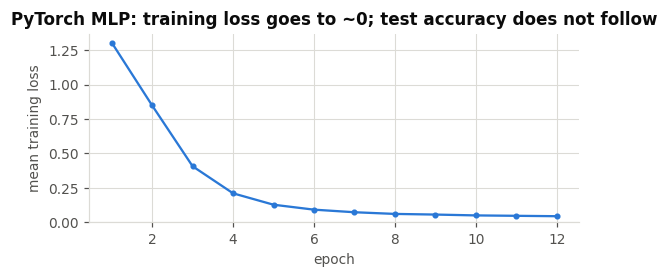

In [26]:
fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.plot(range(1, EPOCHS + 1), history, color=C_BLUE, marker="o", markersize=3)
ax.set_xlabel("epoch")
ax.set_ylabel("mean training loss")
ax.set_title("PyTorch MLP: training loss goes to ~0; test accuracy does not follow")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

### 4.4 The whole road, end to end — and slowly this time

Everything this week taught, in one place, on the business corpus (the same
Northwind support tickets as your assignment): **tokenize → TF-IDF → SVD →
a two-layer network in PyTorch → one honest test score.**

Nothing here is new — it is every step of the week run in order, with **every
line commented in plain English**. The six cells below are self-contained: you
can restart the kernel and run just this section. If PyTorch is new to you,
the gentle companion is [`ism6564-week03-pytorch-intro.ipynb`](ism6564-week03-pytorch-intro.ipynb).

In [27]:
# =============================================================================
# STEP 1 - GET THE DATA READY  (everything in this cell is Week 2 material)
# =============================================================================
# This section is deliberately self-contained: it does not depend on anything
# above it. You can restart the kernel and run cells 4.4 on their own.

import random                      # Python's built-in random numbers
import numpy as np                 # arrays and maths
import pandas as pd                # tables (DataFrames)
import torch                       # PyTorch - the deep-learning library
import torch.nn as nn              # its "neural network" building blocks

# Fix every source of randomness, so this notebook prints the same numbers
# every time it runs. (42 is a convention, not a magic number.)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load the Northwind support tickets straight from the course data repository.
# Same corpus as your assignment: support tickets, each labelled with the
# queue a human dispatcher routed it to. Our job: predict that queue.
URL = ("https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/"
       "week-03-text-classification/data/tickets.csv")
tickets = pd.read_csv(URL).fillna("")        # fillna: blank subjects become "" not NaN

# The text a model sees is the subject and the body glued together ...
tickets["text"] = (tickets["subject"] + " " + tickets["body"]).str.strip()

# ... and we drop exact duplicate resubmissions, so no ticket can end up in
# both the training data and the test data (that would be free marks for the
# model, and a lie in our final score).
tickets = tickets.drop_duplicates("body").reset_index(drop=True)

print(f"{len(tickets)} tickets, {tickets['queue'].nunique()} queues")

2930 tickets, 5 queues


In [28]:
# =============================================================================
# STEP 2 - THREE SPLITS: train / validation / test
# =============================================================================
from sklearn.model_selection import train_test_split

# train (60%)      : the model LEARNS from these tickets.
# validation (20%) : scored after every epoch, to decide WHEN TO STOP training.
# test (20%)       : touched exactly once, at the very end - the honest number.
#
# stratify=tickets["queue"] keeps the queue mix identical in all three pieces,
# so no split accidentally ends up short of a small queue.
train_df, temp_df = train_test_split(
    tickets, test_size=0.40, stratify=tickets["queue"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["queue"], random_state=SEED)

print(f"train {len(train_df)}   val {len(val_df)}   test {len(test_df)}")

train 1758   val 586   test 586


In [29]:
# =============================================================================
# STEP 3 - TEXT BECOMES NUMBERS: TF-IDF, then SVD   (the "prep work")
# =============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import LabelEncoder

# TF-IDF: one column per vocabulary word, each ticket becomes a row of
# weights (bigger = that word says more about this ticket).
# min_df=3 keeps only words that appear in at least 3 tickets - rarer ones
# are mostly typos and one-offs that a model cannot learn from anyway.
#
# THE rule of the week: fit on the TRAINING set only.
#   fit_transform(train) - LEARNS the vocabulary and weights, from train alone
#   transform(val/test)  - places them on the SAME columns, no re-learning
vectorizer = TfidfVectorizer(min_df=3)
X_train = vectorizer.fit_transform(train_df["text"])
X_val   = vectorizer.transform(val_df["text"])
X_test  = vectorizer.transform(test_df["text"])

# SVD: compress the sparse word-columns into 200 dense columns.
# Columns that rise and fall together (refund / refunded / card ...) get
# pooled, so the network downstream sees a smaller, denser, less noisy input.
# Same fit-on-train-only rule - SVD also LEARNS from data.
svd = TruncatedSVD(n_components=200, random_state=SEED)
Z_train = svd.fit_transform(X_train).astype(np.float32)   # float32 = what networks eat
Z_val   = svd.transform(X_val).astype(np.float32)
Z_test  = svd.transform(X_test).astype(np.float32)

# Labels must be numbers too: LabelEncoder maps the 5 queue names to 0..4.
le = LabelEncoder().fit(train_df["queue"])
y_train = le.transform(train_df["queue"])
y_val   = le.transform(val_df["queue"])
y_test  = le.transform(test_df["queue"])

print(f"TF-IDF : {X_train.shape[1]} word columns")
print(f"SVD    : {Z_train.shape[1]} dense columns, keeping "
      f"{svd.explained_variance_ratio_.sum():.1%} of the variance")

TF-IDF : 636 word columns
SVD    : 200 dense columns, keeping 92.5% of the variance


In [30]:
# =============================================================================
# STEP 4 - BUILD THE NETWORK: two layers, nothing fancy
# =============================================================================
# PyTorch computes on tensors (its version of numpy arrays), so convert.
X_train_t = torch.from_numpy(Z_train)          # features: shape (n_tickets, 200)
X_val_t   = torch.from_numpy(Z_val)
X_test_t  = torch.from_numpy(Z_test)
y_train_t = torch.from_numpy(y_train).long()   # labels: integers 0..4
y_val_t   = torch.from_numpy(y_val).long()
y_test_t  = torch.from_numpy(y_test).long()

torch.manual_seed(SEED)     # so the random STARTING weights are reproducible

# The model, read top to bottom like a recipe:
model = nn.Sequential(
    nn.Linear(200, 64),   # layer 1: 200 inputs -> 64 hidden units.
                          #   Each hidden unit computes a weighted sum of all
                          #   200 input numbers, plus a bias - weights the
                          #   training loop will learn.
    nn.ReLU(),            # the activation: negative values become 0.
                          #   Without this bend, two Linear layers would
                          #   collapse into one - the network could learn
                          #   nothing a single layer cannot.
    nn.Linear(64, 5),     # layer 2: 64 hidden values -> 5 scores, one per
                          #   queue. Biggest score = the predicted queue.
)

# How many numbers will training adjust? (weights + biases, per layer)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"parameters: 200*64 + 64  +  64*5 + 5  =  {n_params:,}")

Sequential(
  (0): Linear(in_features=200, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=5, bias=True)
)
parameters: 200*64 + 64  +  64*5 + 5  =  13,189


In [31]:
# =============================================================================
# STEP 5 - TRAIN IT: the five-line loop, plus a validation check each epoch
# =============================================================================
from torch.utils.data import TensorDataset, DataLoader

loss_fn   = nn.CrossEntropyLoss()   # scores how wrong a batch of predictions is
                                    # (the standard choice for multi-class labels)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
                                    # the thing that nudges all 13,189 weights;
                                    # lr = how big each nudge is

# Serve the training tickets in shuffled batches of 200.
loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                    batch_size=200, shuffle=True)

best_val, best_weights, epochs_without_improvement = 0.0, None, 0

for epoch in range(1, 201):                    # up to 200 passes over the data
    model.train()                              # "training mode"
    for xb, yb in loader:                      # one shuffled batch at a time
        optimizer.zero_grad()                  # 1. clear the previous gradients
        predictions = model(xb)                # 2. forward pass: 5 scores per ticket
        loss = loss_fn(predictions, yb)        # 3. how wrong were we?
        loss.backward()                        # 4. work out how to change every weight
        optimizer.step()                       # 5. change them, a little

    # After each epoch, measure on tickets the model did NOT train on:
    model.eval()                               # "evaluation mode"
    with torch.no_grad():                      # just measuring - no gradients needed
        val_acc = (model(X_val_t).argmax(dim=1) == y_val_t).float().mean().item()

    if val_acc > best_val:                     # improved: remember these weights
        best_val = val_acc
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_without_improvement = 0
    else:                                      # not improved for 10 epochs: stop
        epochs_without_improvement += 1
        if epochs_without_improvement >= 10:
            print(f"early stop at epoch {epoch}")
            break

    if epoch == 1 or epoch % 10 == 0:
        print(f"epoch {epoch:3d}   loss {loss.item():.4f}   val accuracy {val_acc:.4f}")

model.load_state_dict(best_weights)            # roll back to the best epoch
print(f"best validation accuracy: {best_val:.4f}")

epoch   1   loss 1.5924   val accuracy 0.3055
epoch  10   loss 1.2208   val accuracy 0.7184


epoch  20   loss 0.5379   val accuracy 0.9164


epoch  30   loss 0.2864   val accuracy 0.9113
early stop at epoch 31
best validation accuracy: 0.9181


In [32]:
# =============================================================================
# STEP 6 - THE HONEST NUMBER: score the test set, once
# =============================================================================
from sklearn.metrics import accuracy_score, f1_score

model.eval()
with torch.no_grad():                          # measuring only
    test_pred = model(X_test_t).argmax(dim=1).numpy()

print(f"test accuracy : {accuracy_score(y_test, test_pred):.4f}")
print(f"test macro-F1 : {f1_score(y_test, test_pred, average='macro'):.4f}")

test accuracy : 0.8976
test macro-F1 : 0.8906


**What to notice, reading back up the road:**

- **The prep did most of the work.** SVD kept 92.5% of the variance in 200
  columns, and the network needed only **13,189 parameters** — about six times
  smaller than the same architecture fed raw TF-IDF — yet this is the best
  test score of any ticket model in the course so far. Smaller, denser, less
  noisy input → a smaller network learns it better.
- **Every "learning" step obeyed the same rule:** the vectorizer, the SVD,
  and the network were all fitted on the training set only.
- **The loop is the same five lines as always** — zero_grad, forward, loss,
  backward, step. From here to Week 4's sequence models, only the layers
  between `nn.Sequential(` and `)` change.

---

### 4.5 The slide deck's ticket-model numbers, reproduced

The Week 3 slides quote a handful of measurements about "our ticket model" —
its coefficients, its confusion matrix, its calibration, what its errors have
in common, and what capacity bought. Course rule: **every number on a slide
must be computable from a notebook.** This section is where those numbers
come from. Same recipe as §4.4's road: seed 42, dedup, 60/20/20 stratified
splits, `TfidfVectorizer(min_df=3)` — the model here is plain logistic
regression, the baseline the deck draws as a one-layer network.

In [33]:
# Self-contained, like §4.4: restart-and-run-this-section works.
import numpy as np
import pandas as pd
import torch  # noqa: F401  (parity with the section above; unused here)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
DATA_URL = ("https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/"
            "week-03-text-classification/data/")

tk = pd.read_csv(DATA_URL + "tickets.csv").fillna("")
tk["text"] = (tk["subject"] + " " + tk["body"]).str.strip()
tk = tk.drop_duplicates("body").reset_index(drop=True)

tr, tmp = train_test_split(tk, test_size=0.40, stratify=tk["queue"], random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["queue"], random_state=SEED)

tvec = TfidfVectorizer(min_df=3)                      # fit on TRAIN only
tXtr = tvec.fit_transform(tr["text"])
tclf = LogisticRegression(max_iter=1000).fit(tXtr, tr["queue"])

# The deck's capacity question needs this model's honest number, so we spend
# the test set here, once — this section IS the reporting artifact.
tpred_te = tclf.predict(tvec.transform(te["text"]))
print(f"parameters: {tclf.coef_.size + tclf.intercept_.size:,} "
      f"({tXtr.shape[1]} features x 5 queues + 5 intercepts)")
print(f"TEST accuracy {accuracy_score(te['queue'], tpred_te):.4f}   "
      f"macro F1 {f1_score(te['queue'], tpred_te, average='macro'):.4f}")

parameters: 3,185 (636 features x 5 queues + 5 intercepts)
TEST accuracy 0.8857   macro F1 0.8772


In [34]:
# --- the coefficients slide: read the weights, per queue --------------------
# A large positive weight = evidence FOR that queue when the term appears.
twords = tvec.get_feature_names_out()
for qi, q in enumerate(tclf.classes_):
    top = np.argsort(tclf.coef_[qi])[::-1][:8]
    row = "  ".join(f"{twords[j]} {tclf.coef_[qi][j]:.2f}" for j in top)
    print(f"{q:18s} {row}")

# Read billing's list closely: charged, card, billing reassure — then the
# confessions. "but", "was", "not" high on the list: the model has learned
# billing tickets are where customers ARGUE — complaint grammar as evidence.
# And "99": the tails of prices ($24.99) as billing evidence. Both fragile.

account-access     account 2.97  email 2.81  log 1.87  longer 1.56  password 1.54  login 1.51  history 1.50  cannot 1.50
billing            charged 2.77  card 2.28  billing 2.22  but 2.09  price 1.85  99 1.84  was 1.82  not 1.80
product-question   does 2.07  or 2.00  will 1.88  stock 1.81  usually 1.75  run 1.53  take 1.52  charge 1.47
returns-warranty   return 4.47  want 3.23  exchange 3.00  label 2.57  warranty 2.41  returnable 2.29  item 1.89  wrong 1.83
shipping           tracking 2.64  has 2.63  delivery 2.58  package 2.53  box 2.16  shipping 2.14  missing 2.04  expedite 1.90


In [35]:
# --- the confusion-matrix slide: validation, read ---------------------------
tpred_va = tclf.predict(tvec.transform(va["text"]))
tqueues = ["shipping", "returns-warranty", "billing", "account-access", "product-question"]
tcm = confusion_matrix(va["queue"], tpred_va, labels=tqueues)
print(pd.DataFrame(tcm, index=[f"true {q}" for q in tqueues],
                       columns=[q.split("-")[0] for q in tqueues]))
print(f"\nvalidation accuracy {accuracy_score(va['queue'], tpred_va):.4f}  (n={len(va)})")
# Biggest off-diagonal cell: shipping tickets sent to returns-warranty — the
# confusable pair, and the two teams who would notice a router first.

                       shipping  returns  billing  account  product
true shipping               161        6        3        1        2
true returns-warranty         2      117        1        3        1
true billing                  3        4      104        4        1
true account-access           0        3        2       62        2
true product-question         4        3        1        4       92

validation accuracy 0.9147  (n=586)


In [36]:
# --- the calibration slide: is a "0.65" really 65%? -------------------------
tproba = tclf.predict_proba(tvec.transform(va["text"]))
tconf = tproba.max(axis=1)
tcorrect = tpred_va == va["queue"].values
print("confidence bucket   n     actually right")
for lo in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    m = (tconf >= lo) & (tconf < lo + 0.1)
    if m.sum():
        print(f"   {lo:.1f}–{lo + 0.1:.1f}       {m.sum():4d}       {tcorrect[m].mean():.2%}")
# The 0.6–0.7 bucket is right ~94% of the time: UNDER-confident. An
# auto-route-above-0.70 rule would send those mostly-tcorrect tickets to a
# human for no reason — check the probability before trusting any threshold.

confidence bucket   n     actually right
   0.4–0.5         31       67.74%
   0.5–0.6         44       75.00%
   0.6–0.7         71       94.37%
   0.7–0.8        152       91.45%
   0.8–0.9        199       96.48%
   0.9–1.0         81       100.00%


In [37]:
# --- the read-the-errors slide: look at what the model gets wrong -----------
terr = np.where(tpred_va != va["queue"].values)[0]
print(f"{len(terr)} validation errors. Read a few (true -> predicted):\n")
for k in terr[:8]:
    row = va.iloc[k]
    print(f"[{row['queue']:>16s} -> {tpred_va[k]:<16s}] {row['text'][:110]}")
# The pattern that jumps out of reading: tickets that ask TWO things at once.
# The dispatcher rule labels them by the FIRST intent; the model reads the
# whole bag of twords, and both intents pull on it.

50 validation errors. Read a few (true -> predicted):

[returns-warranty -> shipping        ] Problem with my order Hey, I want to return the Riverbend sandals from order NW-59171 for a refund. only half 
[  account-access -> billing         ] Need assistance Hey, I cannot log in to my account - it keeps saying my password is wrong even after I reset i
[returns-warranty -> account-access  ] Defective tiem The Trailhead hiking boots does not fit - how do I exchange it for the wide version. the email 
[  account-access -> product-question] Support request the verification link in the signup email says it has expired. is the torrent rain jacket actu
[         billing -> product-question] Need assistance Hi, You charged the wrong card - the order should have gone on the card ending 7069. is the ri
[         billing -> account-access  ] Membership billing Hey, I returned the Merino trail socks and the refund I got was $189.99 short of what I pai
[         billing -> account-access  ] Urgent

**The cohort, quantified.** Using the instructor's annotation file (which
flags which tickets are genuinely two-intent — it is not distributed with the
course data), the reading above generalizes: the two-intent cohort is **87 of
586** validation tickets and carries **44 of the 50 errors** — an error rate
of **50.6%** inside the cohort against **1.2%** outside it. One mercy, also
measured: the model *knows* it is confused — mean confidence **0.61** on
two-intent tickets vs **0.79** elsewhere — which is why a routing threshold
catches many of them. You will meet this cohort yourself in Assignment
Task 5, on your own split.

**What capacity bought — the deck's three-model table, sourced:**

| model | parameters | test acc | where computed |
|---|---:|---:|---|
| logistic regression | 3,185 | 0.8857 | the cell above |
| network, raw TF-IDF (636→128→5) | 82,181 | 0.8959 | `ism6564-week03-pytorch-step-by-step.ipynb` |
| network, SVD-200 (200→64→5) | 13,189 | 0.8976 | §4.4 |

Three models spanning 26× in size, one point apart — at this scale the road
matters more than the vehicle.

---

## 5 — Evaluation, honestly

Everything so far has been reported as accuracy and macro-F1 because those are
the two numbers you can compare across a table. Neither is sufficient. This
section is the part of the week that transfers to every project you will do
after this course.

### 5.1 Per-class, always

`classification_report` first, aggregate numbers second. An aggregate is a
weighted average of things you should have looked at individually.

In [38]:
print("logistic regression, per class:\n")
print(classification_report(y_te, pred_lr, target_names=SHORT, digits=3))

logistic regression, per class:

              precision    recall  f1-score   support

     atheism      0.779     0.630     0.697       319
    graphics      0.834     0.918     0.874       389
         med      0.875     0.869     0.872       396
   christian      0.804     0.854     0.828       398

    accuracy                          0.827      1502
   macro avg      0.823     0.818     0.818      1502
weighted avg      0.825     0.827     0.824      1502



### 5.2 macro vs micro vs weighted — and when each one lies

Three averages of the same per-class F1 scores:

- **macro** — unweighted mean over classes. Every class counts the same,
  however rare.
- **weighted** — mean weighted by class support. Big classes dominate.
- **micro** — pool all true positives, false positives and false negatives
  first, then compute one F1. **In single-label multiclass this equals
  accuracy**, always. Not approximately: identically.

In [39]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
for name, pred in [("logistic regression", pred_lr),
                   ("random forest (sparse)", rf.predict(X_te)),
                   ("kNN cosine", KNeighborsClassifier(15, metric="cosine")
                    .fit(X_tr, y_tr).predict(X_te))]:
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_te, pred),
        "micro F1": f1_score(y_te, pred, average="micro"),
        "macro F1": f1_score(y_te, pred, average="macro"),
        "weighted F1": f1_score(y_te, pred, average="weighted"),
        f"F1 {SHORT[0]}": f1_score(y_te, pred, average=None)[0],
    })
comp = pd.DataFrame(rows).set_index("model").round(4)
print(comp.to_string())
print(f"\nmicro F1 == accuracy exactly? "
      f"{np.allclose(comp['micro F1'], comp['accuracy'])}")

p, r, f, s = precision_recall_fscore_support(y_te, pred_lr)
print("\nlogistic regression, per class:")
print(pd.DataFrame({"class": SHORT, "precision": p.round(3), "recall": r.round(3),
                    "F1": f.round(3), "support": s}).to_string(index=False))
print(f"\nmacro F1    = plain mean of the F1 column = {f.mean():.4f}")
print(f"weighted F1 = support-weighted mean        = {np.average(f, weights=s):.4f}")
print(f"gap (weighted - macro)                     = {np.average(f, weights=s) - f.mean():+.4f}")

                        accuracy  micro F1  macro F1  weighted F1  F1 atheism
model                                                                        
logistic regression       0.8269    0.8269    0.8177       0.8237      0.6967
random forest (sparse)    0.7636    0.7636    0.7481       0.7563      0.5814
kNN cosine                0.8029    0.8029    0.7969       0.8012      0.7092

micro F1 == accuracy exactly? True

logistic regression, per class:
    class  precision  recall    F1  support
  atheism      0.779   0.630 0.697      319
 graphics      0.834   0.918 0.874      389
      med      0.875   0.869 0.872      396
christian      0.804   0.854 0.828      398

macro F1    = plain mean of the F1 column = 0.8177
weighted F1 = support-weighted mean        = 0.8237
gap (weighted - macro)                     = +0.0060


The gap between weighted and macro is the smallest class being quietly carried
by the big ones. Here it is only +0.006, because the imbalance is mild — 21.3%
versus 26.5%.

But look at what *both* aggregates are hiding. `alt.atheism` scores **0.697**
and every other class scores above 0.82. Its recall is 0.630, so the model
misses **37% of atheism posts**. Accuracy says 0.827, macro F1 says 0.818, and
neither number contains the sentence "one class in four is broken".

Now imagine the class you care about is 2% of the data, as an escalation flag
in a support queue is. Weighted F1 would be almost entirely determined by the
class you do not care about, and would move by less than a point if the class
you *do* care about stopped working entirely.

**The rule:** report macro when every class matters equally regardless of
frequency (which is usually the case when the rare class is the interesting
one). Report weighted when you care about expected performance on a random
incoming document. Report micro only if you enjoy saying "accuracy" twice.

### 5.3 The confusion matrix names the failure

`alt.atheism` scores 13 points of F1 below every other class. That tells you
something is wrong; it does not tell you what. The confusion matrix does.

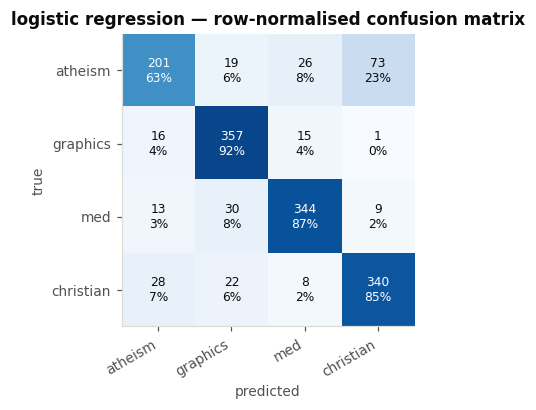

largest off-diagonal cells:
   73  true atheism   -> predicted christian
   30  true med       -> predicted graphics
   28  true christian -> predicted atheism
   26  true atheism   -> predicted med


In [40]:
cm = confusion_matrix(y_te, pred_lr)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), SHORT, rotation=30, ha="right")
ax.set_yticks(range(4), SHORT)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("logistic regression — row-normalised confusion matrix")
ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center",
                fontsize=8, color="white" if cm_norm[i, j] > 0.5 else INK)
plt.tight_layout()
plt.show()

off = [(cm[i, j], SHORT[i], SHORT[j]) for i in range(4) for j in range(4) if i != j]
print("largest off-diagonal cells:")
for n, a, b in sorted(off, reverse=True)[:4]:
    print(f"  {n:3d}  true {a:9s} -> predicted {b}")

### 5.4 Class imbalance: where accuracy and ROC both lie

The corpus above is nearly balanced. Real text problems rarely are, so build
one that is not: **is this post about a medical problem?** — `sci.med` against
everything else, with the positive class subsampled to about 4% of the data.
That is roughly the prevalence of a "needs clinical review" or "needs
escalation" flag in a live queue, and it is the shape of nearly every text
classification problem anyone pays for.

In [41]:
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve, recall_score, precision_score)

rs = np.random.default_rng(7)


POS = SHORT.index("med")


def imbalance(docs, y, n_pos):
    pos = np.where(y == POS)[0]
    neg = np.where(y != POS)[0]
    keep = np.sort(np.concatenate([rs.choice(pos, n_pos, replace=False), neg]))
    return [docs[i] for i in keep], (y[keep] == POS).astype(int)


d_tr_i, y_tr_i = imbalance(docs_tr, y_tr, 90)
d_te_i, y_te_i = imbalance(docs_te, y_te, 45)
print(f"train {len(y_tr_i)} docs, {y_tr_i.mean():.2%} positive")
print(f"test  {len(y_te_i)} docs, {y_te_i.mean():.2%} positive\n")

vi = TfidfVectorizer(**TFIDF_KW)
Ai, Bi = vi.fit_transform(d_tr_i), vi.transform(d_te_i)
mi = LogisticRegression(max_iter=2000, C=10).fit(Ai, y_tr_i)
scores_i = mi.predict_proba(Bi)[:, 1]
pred_i = mi.predict(Bi)

print(f"accuracy of the model                : {accuracy_score(y_te_i, pred_i):.4f}")
print(f"accuracy of 'always say no'          : {1 - y_te_i.mean():.4f}")
print(f"ROC-AUC                              : {roc_auc_score(y_te_i, scores_i):.4f}   <- looks excellent")
print(f"average precision (area under PR)    : {average_precision_score(y_te_i, scores_i):.4f}")
print(f"  ... against a random-guess AP of   : {y_te_i.mean():.4f}")
print()
print(f"recall on the positive class @0.5    : {recall_score(y_te_i, pred_i):.4f}   <- the truth")
print(f"precision on the positive class @0.5 : {precision_score(y_te_i, pred_i, zero_division=0):.4f}")
print(f"positives found: {int((pred_i * y_te_i).sum())} of {int(y_te_i.sum())}")

train 1753 docs, 5.13% positive
test  1151 docs, 3.91% positive



accuracy of the model                : 0.9635
accuracy of 'always say no'          : 0.9609
ROC-AUC                              : 0.9617   <- looks excellent
average precision (area under PR)    : 0.7694
  ... against a random-guess AP of   : 0.0391

recall on the positive class @0.5    : 0.0667   <- the truth
precision on the positive class @0.5 : 1.0000
positives found: 3 of 45


Four numbers describing one model:

- **Accuracy 0.9635** — and a model that always says "no" scores 0.9609. The
  entire apparent performance is the majority class. Nothing was learned that
  a constant could not have produced.
- **ROC-AUC 0.9617** — because the false-positive rate has 1,106 negatives in
  its denominator, so even a hundred false positives move it by 9%. **ROC is
  insensitive to the negative class being enormous, which is precisely the
  property you do not want here.**
- **Average precision 0.7694** against a random-guess floor of 0.0391 — a real
  signal, and 20× better than chance. The model *has* learned something.
- **Recall 0.0667** — it fires 3 times out of 45. It finds one flagged case in
  fifteen and lets fourteen through.

Precision 1.0 with recall 0.067 is the signature of a model that has learned
"say no unless you are certain", because that is exactly what minimising log
loss on a 96%-negative dataset rewards. Note that AP and ROC-AUC both describe
the *ranking*, which is good; accuracy and recall describe what `predict()`
actually does at its default threshold, which is useless.

The precision-recall curve uses precision, whose denominator is *predicted*
positives, so it cannot be rescued by a large negative class.

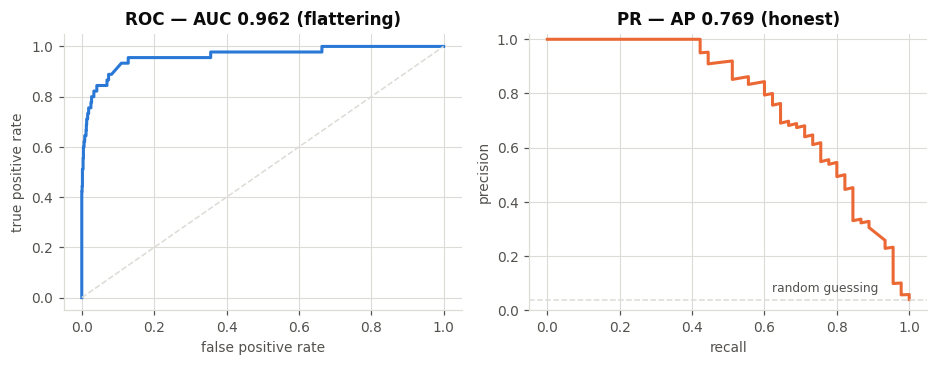

moving the decision threshold — the knob 0.5 hides:



 threshold  precision  recall    F1  flagged
      0.50      1.000   0.067 0.125        3
      0.30      1.000   0.178 0.302        8
      0.20      1.000   0.400 0.571       18
      0.10      0.794   0.600 0.684       34
      0.05      0.529   0.800 0.637       68


In [42]:
fpr, tpr, _ = roc_curve(y_te_i, scores_i)
prec, rec, thr = precision_recall_curve(y_te_i, scores_i)

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
axes[0].plot(fpr, tpr, color=C_BLUE, lw=2)
axes[0].plot([0, 1], [0, 1], color=GRIDC, ls="--", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate",
            title=f"ROC — AUC {roc_auc_score(y_te_i, scores_i):.3f} (flattering)")
axes[1].plot(rec, prec, color=C_ORANGE, lw=2)
axes[1].axhline(y_te_i.mean(), color=GRIDC, ls="--", lw=1)
axes[1].set(xlabel="recall", ylabel="precision", ylim=(0, 1.02),
            title=f"PR — AP {average_precision_score(y_te_i, scores_i):.3f} (honest)")
axes[1].annotate("random guessing", (0.62, y_te_i.mean() + 0.03), color=INK_2, fontsize=8)
plt.tight_layout()
plt.show()

print("moving the decision threshold — the knob 0.5 hides:\n")
rows = []
for t in (0.5, 0.3, 0.2, 0.1, 0.05):
    pk = (scores_i >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": round(precision_score(y_te_i, pk, zero_division=0), 3),
                 "recall": round(recall_score(y_te_i, pk), 3),
                 "F1": round(f1_score(y_te_i, pk), 3),
                 "flagged": int(pk.sum())})
print(pd.DataFrame(rows).to_string(index=False))

`0.5` is not a law of nature — it is `predict()`'s default, and it is only
optimal if your costs are symmetric and your classes balanced. Neither holds
here. Choosing the threshold from the business cost of a miss versus a false
alarm is part of building the model, not an afterthought.

### 5.5 Calibration: is `predict_proba` a probability?

`predict_proba` returns numbers in [0, 1] that sum to 1. That does **not** make
them probabilities. A model is *calibrated* if, among the cases where it says
0.8, about 80% are actually correct. Anything that thresholds on confidence —
auto-route above 0.9, escalate to a human below 0.6 — depends on this and
nothing else.

Two summary numbers, both computed here rather than eyeballed:
**Brier score** (mean squared error against the one-hot truth; lower is better)
and **expected calibration error** (mean gap between stated confidence and
observed accuracy, bucketed).

In [43]:
Y_onehot = np.eye(len(CATS))[y_te]


def ece(conf, correct, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total


prob_models = {
    "logistic regression": logreg,
    "LinearSVC + Platt": svc_cal,
    "random forest": rf,
    "MLP (sklearn)": mlp,
}

rows, curves = [], {}
for name, m in prob_models.items():
    P = m.predict_proba(X_te)
    conf = P.max(1)
    correct = (P.argmax(1) == y_te).astype(float)
    rows.append({"model": name,
                 "accuracy": round(accuracy_score(y_te, P.argmax(1)), 4),
                 "mean confidence": round(conf.mean(), 4),
                 "Brier (multiclass)": round(np.mean(np.sum((P - Y_onehot) ** 2, 1)), 4),
                 "ECE": round(ece(conf, correct), 4)})
    bins = np.linspace(0.25, 1.0, 9)
    xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m_ = (conf > lo) & (conf <= hi)
        if m_.sum() >= 15:
            xs.append(conf[m_].mean())
            ys.append(correct[m_].mean())
    curves[name] = (xs, ys)

print(pd.DataFrame(rows).to_string(index=False))

print("\nwhat a 'auto-route only above 0.90 confidence' gate would do:\n")
gate = []
for name, m in prob_models.items():
    P = m.predict_proba(X_te)
    conf, correct = P.max(1), (P.argmax(1) == y_te)
    hi = conf >= 0.90
    gate.append({"model": name,
                 "auto-routed": f"{hi.sum():4d} / {len(y_te)}",
                 "share": f"{hi.mean():.1%}",
                 "accuracy when it fires": round(correct[hi].mean(), 4) if hi.sum() else float("nan"),
                 "accuracy on the rest": round(correct[~hi].mean(), 4)})
print(pd.DataFrame(gate).to_string(index=False))

              model  accuracy  mean confidence  Brier (multiclass)    ECE
logistic regression    0.8269           0.7368              0.2670 0.0901
  LinearSVC + Platt    0.8269           0.7973              0.2481 0.0329
      random forest    0.7636           0.5912              0.3775 0.1725
      MLP (sklearn)    0.8289           0.7424              0.2528 0.0939

what a 'auto-route only above 0.90 confidence' gate would do:

              model auto-routed share  accuracy when it fires  accuracy on the rest
logistic regression  485 / 1502 32.3%                  0.9794                0.7542
  LinearSVC + Platt  645 / 1502 42.9%                  0.9690                0.7200
      random forest   71 / 1502  4.7%                  0.9859                0.7526
      MLP (sklearn)  517 / 1502 34.4%                  0.9826                0.7482


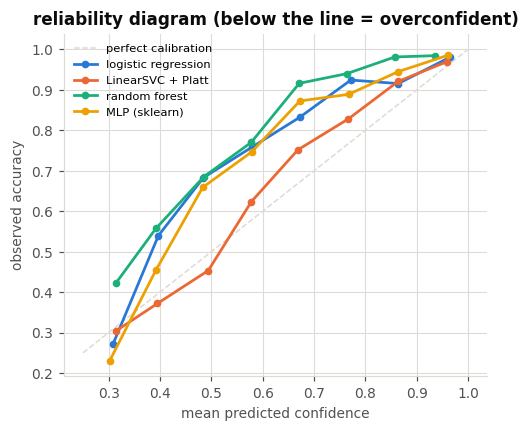

In [44]:
fig, ax = plt.subplots(figsize=(4.6, 4.0))
ax.plot([0.25, 1], [0.25, 1], color=GRIDC, ls="--", lw=1, label="perfect calibration")
for (name, (xs, ys)), c in zip(curves.items(), SERIES):
    ax.plot(xs, ys, marker="o", markersize=4, color=c, lw=1.8, label=name)
ax.set(xlabel="mean predicted confidence", ylabel="observed accuracy",
       title="reliability diagram (below the line = overconfident)")
ax.legend(fontsize=7.5, loc="upper left")
plt.tight_layout()
plt.show()

Read the table with the diagram, and note that the failure runs in the
direction most people do not expect. Every curve sits **above** the diagonal:
these models are systematically **under**confident.

- The **random forest** is the extreme case — ECE 0.30, Brier score twice
  everyone else's. Its "probabilities" are vote fractions over 300 trees, and
  300 deep decorrelated trees essentially never vote unanimously, so the score
  is squashed toward the middle. In the 0.48 bucket it is right 90% of the
  time. Its mean confidence over the whole test set is 0.51 while its accuracy
  is 0.81.
- **Platt-scaled `LinearSVC`** has the best Brier score and an ECE half that of
  the next-best model. That is not luck: it is the quantity
  `CalibratedClassifierCV` exists to optimise.
- **Logistic regression is not automatically calibrated either** — ECE 0.13.
  Maximum-likelihood fitting calibrates on the *training* distribution, and the
  `C=10` L2 penalty shrinks the coefficients, which pulls test-time
  probabilities toward uniform.

The gate table underneath makes the consequence concrete. An "auto-route above
0.90 confidence" rule clears **43% of the queue** with the calibrated model,
32% with logistic regression, and **4.7%** with the random forest — at
essentially the same accuracy on everything each one does clear (0.969 to
0.986). The forest is not less trustworthy above its own 0.90; it simply almost
never gets there, so it can automate nothing. Same corpus, same task, nine
times the throughput difference — decided entirely by calibration, not by
accuracy.

A model can rank perfectly and still be badly calibrated. If your system only
sorts, ranking is enough. The moment a *number* crosses a threshold and
triggers an action, calibration is the property that decides what your system
can do.

### 5.6 *(reference — beyond what class covers)* Per-slice performance

One aggregate number hides every subgroup. Slice by anything you have — here,
document length, which we have for free.

slice          length   n  accuracy  macro F1
   Q1     0-43 tokens 371    0.6496    0.6270
   Q2    43-93 tokens 375    0.8453    0.8254
   Q3   93-217 tokens 378    0.9048    0.9013
   Q4 217-9196 tokens 378    0.9048    0.8981

overall accuracy 0.8269 = a weighted average that hides a 26-point spread


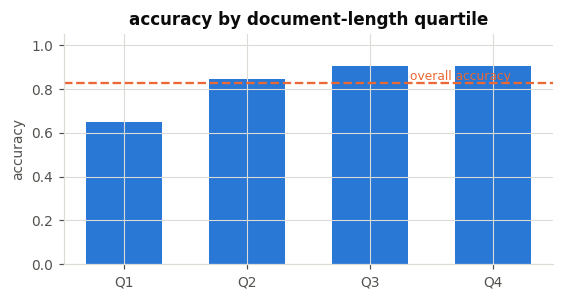

In [45]:
lens_te = np.array([len(d.split()) for d in docs_te])
edges = np.quantile(lens_te, [0, .25, .5, .75, 1.0])

rows = []
for i in range(4):
    m = (lens_te >= edges[i]) & (lens_te <= edges[i + 1] if i == 3
                                 else lens_te < edges[i + 1])
    rows.append({"slice": f"Q{i + 1}",
                 "length": f"{edges[i]:.0f}-{edges[i + 1]:.0f} tokens",
                 "n": int(m.sum()),
                 "accuracy": round(accuracy_score(y_te[m], pred_lr[m]), 4),
                 "macro F1": round(f1_score(y_te[m], pred_lr[m], average="macro"), 4)})
slices = pd.DataFrame(rows)
print(slices.to_string(index=False))
print(f"\noverall accuracy {accuracy_score(y_te, pred_lr):.4f} "
      f"= a weighted average that hides a "
      f"{(slices['accuracy'].max() - slices['accuracy'].min()) * 100:.0f}-point spread")

fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.bar(slices["slice"], slices["accuracy"], color=C_BLUE, width=0.62)
ax.axhline(accuracy_score(y_te, pred_lr), color=C_ORANGE, ls="--", lw=1.5)
ax.annotate("overall accuracy", (3.15, accuracy_score(y_te, pred_lr) + 0.012),
            color=C_ORANGE, fontsize=8, ha="right")
ax.set(ylim=(0, 1.05), ylabel="accuracy",
       title="accuracy by document-length quartile")
plt.tight_layout()
plt.show()

**Twenty-six points of accuracy** separate the shortest quartile (0.650) from
the longest (0.905). The headline 0.827 describes no actual subgroup — it is
the average of a model that works and a model that does not.

If the incoming traffic in production skews shorter than your test set — and
for a support queue, a chat widget, or a subject-line classifier it certainly
will — your reported accuracy is an overestimate before you ship a line.

This is one slice, on the one feature we happened to have for free. Do it for
every segment you can name: channel, language, customer tier, time of day.

Note what Q1 is: documents of **0 to 43 tokens**, at 0.650. Hold that thought
for exactly one section.

### 5.7 Error analysis — the part nobody budgets time for

Not optional, not a bonus. Sort the mistakes by the model's own confidence and
read them. Start with the *least* confident predictions, which is where a
model tells you it is lost.

In [46]:
P_lr = logreg.predict_proba(X_te)
conf_lr = P_lr.max(1)
order = np.argsort(conf_lr)

print("the 10 least confident test predictions\n")
rows = []
for i in order[:10]:
    rows.append({"idx": i,
                 "conf": round(conf_lr[i], 4),
                 "true": SHORT[y_te[i]],
                 "pred": SHORT[pred_lr[i]],
                 "n_tokens": len(docs_te[i].split()),
                 "text": repr(docs_te[i][:60])})
print(pd.DataFrame(rows).to_string(index=False))

the 10 least confident test predictions

 idx   conf      true      pred  n_tokens                                                                text
 263 0.2620   atheism   atheism       135      ': >Prove it. I have a source that says that to date, the civ'
1489 0.2767   atheism   atheism       150      ': This figure, is far below all the other figures I have see'
1488 0.2798  graphics   atheism        54      "What I'd like to see is the more generic N-dimensional widge"
 431 0.2812   atheism       med         6                           "This is hell.  Hasn't anyone noticed?\n"
 837 0.2848       med       med         6                    "\n\n\nGee, I'd FORGOTTEN about THIS NUT.\n\n\n"
 932 0.2875   atheism   atheism        29 '\n\n\n[stuff deleted]\n\nActually, you get a ton of weapons and a'
 172 0.2891  graphics   atheism        40     "\nI don't know the answer the to this one, although with 8-bi"
1325 0.2900       med   atheism        26   "\n\n\nNonsense! I've taught fifth,

Two patterns in ten rows. Half of them are very short — 6, 13, 19, 26 tokens —
which is §5.6's Q1 result showing up one document at a time. The rest are
**quoted arguments**: `'>Prove it. I have a source that says...'` is one side
of a debate reproduced inside the other side's post, which is §5.8's problem
arriving early.

Notice also that the model was *right* on five of these ten. Low confidence is
not the same as wrong; it is the model correctly reporting that it is close to
a decision boundary. That is a usable signal — §5.5's gate is built on it.

There is a second question worth asking of any `predict_proba` output, and
almost nobody asks it: **are any two rows identical?** Different documents
should produce different probabilities. A repeated row means two inputs became
the same thing somewhere in the pipeline.

In [47]:
# how many test documents share their exact probability vector with another?
uniq, inverse, counts = np.unique(P_lr.round(10), axis=0,
                                  return_inverse=True, return_counts=True)
dupes = counts[counts > 1]
print(f"{len(P_lr):,} test documents produced {len(uniq):,} distinct probability rows")
print(f"repeated rows: {len(dupes)}  covering {dupes.sum()} documents\n")

biggest = int(np.argmax(counts))
members = np.where(inverse == biggest)[0]
print(f"the largest group has {len(members)} documents, all with probability "
      f"{uniq[biggest].round(4)}")
print(f"their true labels: {np.bincount(y_te[members], minlength=4)}  (by class)")
print(f"accuracy on them : {accuracy_score(y_te[members], pred_lr[members]):.4f}")
print("\nfirst five of them, raw:")
for i in members[:5]:
    print(f"  {repr(docs_te[i][:70])}")

1,502 test documents produced 1,455 distinct probability rows
repeated rows: 3  covering 50 documents

the largest group has 46 documents, all with probability [0.2284 0.303  0.3017 0.1669]
their true labels: [ 9  7 16 14]  (by class)
accuracy on them : 0.1522

first five of them, raw:
  ' \n \nHere we go again.\n \n=============================================='
  ''
  'Then there are always osteopathy colleges....\n'
  ''
  ''


Forty-six documents, one probability vector, byte for byte. That does not
happen by chance — it happens when forty-six different inputs land on the same
point in feature space. There is only one point that many unrelated documents
can share.

In [48]:
row_sums_tr = np.asarray(X_tr.sum(1)).ravel()
row_sums_te = np.asarray(X_te.sum(1)).ravel()
empty_tr = row_sums_tr == 0
empty_te = row_sums_te == 0

print(f"all-zero TF-IDF rows in training: {empty_tr.sum():3d} of {X_tr.shape[0]:,}"
      f"  ({empty_tr.mean():.1%})")
print(f"all-zero TF-IDF rows in test    : {empty_te.sum():3d} of {X_te.shape[0]:,}"
      f"  ({empty_te.mean():.1%})")
print()
raw_lens = np.array([len(docs_te[i].strip()) for i in np.where(empty_te)[0]])
print(f"of the {empty_te.sum()} empty test rows, {(raw_lens == 0).sum()} have a "
      f"completely empty raw string;")
print(f"the other {(raw_lens > 0).sum()} still have text — every word of which our own "
      f"preprocessing removed.")
print("\nexamples of the non-empty-but-still-zero ones:")
for i in np.where(empty_te)[0]:
    if len(docs_te[i].strip()) > 0:
        print(f"  {repr(docs_te[i][:70])}")

all-zero TF-IDF rows in training:  54 of 2,257  (2.4%)
all-zero TF-IDF rows in test    :  46 of 1,502  (3.1%)

of the 46 empty test rows, 41 have a completely empty raw string;
the other 5 still have text — every word of which our own preprocessing removed.

examples of the non-empty-but-still-zero ones:
  ' \n \nHere we go again.\n \n=============================================='
  'Then there are always osteopathy colleges....\n'
  '\n\nAnd for the Commodore CDTV.\n'
  '\n\nIt is still incestuous.... :)\n\n'
  'Where can I find it ?'


There they are: **46 test documents and 54 training documents whose TF-IDF row
is entirely zero.**

Three distinct causes, and only the first is anybody's fault but ours:

- **41** were emptied by `remove=("headers", "footers", "quotes")` — the post
  was *nothing but* a quoted reply and a signature. Not a bug; the post really
  did contain no original text.
- A handful survive as real English but consist only of stopwords —
  `'Here we go again.'` — which `stop_words="english"` then deletes. Not a bug
  either, but the label is unrecoverable.
- The rest, like `'Then there are always osteopathy colleges....'`, lost every
  content word to `min_df=2`. **That one is on us.** Our own preprocessing
  choice created it, and a different `min_df` would not have.

The consequences ripple through everything above:

In [49]:
from scipy.special import softmax

P_empty = P_lr[empty_te]
print(f"are all {empty_te.sum()} empty-document probability rows identical? "
      f"{np.allclose(P_empty, P_empty[0])}")
print(f"the row      : {P_empty[0].round(4)}")
print(f"softmax(intercept_): {softmax(logreg.intercept_).round(4)}")
print(f"identical?   : {np.allclose(P_empty[0], softmax(logreg.intercept_))}")
print(f"class priors : {(np.bincount(y_tr) / len(y_tr)).round(4)}")
print()
print(f"accuracy on the {empty_te.sum()} empty test documents : "
      f"{accuracy_score(y_te[empty_te], pred_lr[empty_te]):.4f}")
print(f"accuracy on the {(~empty_te).sum()} non-empty ones      : "
      f"{accuracy_score(y_te[~empty_te], pred_lr[~empty_te]):.4f}")
print(f"overall                                    : {accuracy_score(y_te, pred_lr):.4f}")

are all 46 empty-document probability rows identical? True
the row      : [0.2284 0.303  0.3017 0.1669]
softmax(intercept_): [0.2284 0.303  0.3017 0.1669]
identical?   : True
class priors : [0.2127 0.2588 0.2632 0.2654]

accuracy on the 46 empty test documents : 0.1522
accuracy on the 1456 non-empty ones      : 0.8482
overall                                    : 0.8269


With `x = 0` the model reduces to `softmax(intercept_)` — a constant. It is not
classifying, it is guessing, identically, every time. And the guess is not even
the class prior, because the intercept was fit jointly with 12,959 regularised
coefficients.

Then look at the accuracy on those rows: **0.1522**. Not 0.25, which is what
uniform guessing would give on four classes — *worse* than chance. The constant
it always predicts is `comp.graphics`, and only 7 of the 46 empty documents
happen to be `comp.graphics` posts. A model that always guesses one class
scores that class's share, and here that share is 15%.

Excluding them, test accuracy is 0.8482 rather than 0.8269 — those 46 documents
cost 2.1 points of headline accuracy while contributing nothing but noise.

**Now go back to §2.4.** A zero vector sits at distance 0 from the origin. For
a unit-length query, the Euclidean distance to a zero vector is exactly
$\|q\| = 1$, while the distance to a genuinely similar document is
$\sqrt{2 - 2\cos} \approx 1.39$. So under Euclidean distance **every one of
the 54 empty training documents is closer to every query than any real
document is.** They are the 15 nearest neighbours of essentially the entire
test set, and they all vote for whatever their arbitrary labels happen to
be.

In [50]:
D = pairwise_distances(X_te[:200], X_tr, metric="euclidean")
print(f"mean Euclidean distance from a test doc to an EMPTY training doc : "
      f"{D[:, empty_tr].mean():.4f}")
print(f"mean Euclidean distance to a NON-EMPTY training doc              : "
      f"{D[:, ~empty_tr].mean():.4f}")
Dc_ = pairwise_distances(X_te[:200], X_tr, metric="cosine")
print(f"mean COSINE distance to an empty training doc                    : "
      f"{Dc_[:, empty_tr].mean():.4f}   <- sklearn's maximum")
print()
print("kNN accuracy, before and after dropping the all-zero TRAINING rows:\n")
for metric in ("cosine", "euclidean"):
    before = KNeighborsClassifier(15, metric=metric).fit(X_tr, y_tr)
    after = KNeighborsClassifier(15, metric=metric).fit(X_tr[~empty_tr], y_tr[~empty_tr])
    a_before = accuracy_score(y_te, before.predict(X_te))
    a_after = accuracy_score(y_te, after.predict(X_te))
    print(f"  {metric:9s}  with the empty rows {a_before:.4f}   "
          f"without them {a_after:.4f}   ({a_after - a_before:+.4f})")

mean Euclidean distance from a test doc to an EMPTY training doc : 0.9650
mean Euclidean distance to a NON-EMPTY training doc              : 1.3900
mean COSINE distance to an empty training doc                    : 1.0000   <- sklearn's maximum

kNN accuracy, before and after dropping the all-zero TRAINING rows:



  cosine     with the empty rows 0.8029   without them 0.8089   (+0.0060)


  euclidean  with the empty rows 0.2417   without them 0.8089   (+0.5672)


Euclidean-kNN goes from **0.2417 to 0.8089** — a 57-point jump from deleting 54
rows — and the two metrics now agree to four decimal places, exactly as the
algebra in §2.4 said they must. Cosine was never affected, because sklearn
defines the cosine distance to a zero vector as 1.0, the *maximum*. Under
cosine the empty documents are the furthest thing from every query instead of
the nearest.

Four hours of "why is my kNN broken", solved by reading ten rows of output.

Three lessons, in order of how much they will cost you:

1. **The bug was in the data, and only one model family reacted to it.**
   Logistic regression absorbed 54 uninformative rows without complaint. kNN
   lost 57 points of accuracy. A silent data defect does not show up equally
   in every model — which is an argument for fitting more than one.
2. **The tool did not warn us.** No exception, no warning. `fit` succeeded,
   `predict` returned an array of the right shape, and the number looked
   plausible enough to put on a slide.
3. **Aggregate metrics hid it.** 46 documents out of 1,502 can only move
   overall accuracy by about 2 points. §5.6's per-slice view *nearly* caught
   it — that Q1 number, 0.650 on documents of 43 tokens or fewer — and error
   analysis caught it outright.

What you do about it is a design decision, not a cleanup: drop them, route them
to a human, or return an explicit `insufficient_text` outcome. **Silently
predicting a class for a document with no text is the one option that is
always wrong.**

### 5.8 The other errors — what the model actually learned

Empty documents accounted for 39 of the errors. There are 221 more. Read the
mistakes the model was *sure* about — those are the ones where it has learned
something wrong rather than learned nothing.

In [51]:
wrong = np.where((pred_lr != y_te) & (~empty_te))[0]
wrong = wrong[np.argsort(conf_lr[wrong])[::-1]]      # most confident errors first

print(f"{len(wrong)} confident (non-empty) errors. The 5 most confident:\n")
for i in wrong[:5]:
    print(f"--- conf {conf_lr[i]:.3f}  true={SHORT[y_te[i]]}  pred={SHORT[pred_lr[i]]} ---")
    print("   ", " ".join(docs_te[i].split())[:230], "\n")

pair = pd.crosstab(pd.Series([SHORT[i] for i in y_te], name="true"),
                   pd.Series([SHORT[i] for i in pred_lr], name="pred"))
print(pair.to_string())

221 confident (non-empty) errors. The 5 most confident:

--- conf 0.983  true=atheism  pred=christian ---
    BR> From: wpr@atlanta.dg.com (Bill Rawlins) BR> Newsgroups: alt.atheism BR> Organization: DGSID, Atlanta, GA BR> Since you have referred to the Messiah, I assume you BR> are referring to the New Testament. Please detail BR> your c 

--- conf 0.974  true=atheism  pred=christian ---
    I found this little gem, I don't know if anyone has any interest/comments... -------------------------------------------------------------------------------- Hi everyone, I'm a commited Christian that is battling with a problem. I 

--- conf 0.974  true=atheism  pred=christian ---
    But if He/She did you would probably consider it rape. Obviously there are many Christians who have tried and do believe. So .. ? No one asks you to swallow everything, in fact Jesus warns against it. But let me ask you a question 

--- conf 0.972  true=atheism  pred=christian ---
    RAPTURE - OCTOBER 28, 1992 WHAT 

Read those five posts. **Every one is truly `alt.atheism` and confidently
predicted `soc.religion.christian`**, and the confusion matrix agrees that this
is the model's dominant failure: 73 atheism posts sent to christian, against
28 in the other direction.

Then read what they actually say. The first quotes a Christian correspondent at
length before rebutting him. The third is an atheist answering a believer's
argument. The fourth reproduces a rapture tract *in order to mock it*. All four
are, word for word, mostly Christian vocabulary — `god`, `jesus`, `christ`,
`faith`, `scripture` — because **that is what you have to say in order to argue
against it.**

This is the representation's ceiling stated as concretely as it gets. The two
classes are not distinguished by *which* words appear. They are distinguished
by the **stance** taken toward them, which lives in negation, quotation,
sarcasm and sentence structure — every one of which a bag of words discards
before the classifier ever runs.

No amount of tuning fixes that, and neither does a bigger model over the same
features. §6.3 measures exactly how much information the representation is
throwing away.

---

## 6 — Model selection

### 6.1 Grid search over the whole `Pipeline`

Tune the vectorizer and the classifier **together**. `min_df` and `C` interact:
a bigger vocabulary needs more regularisation. Tuning them separately finds a
worse pair than tuning them jointly, and `Pipeline` parameter names
(`step__param`) are what make joint tuning one line.

Note what the search is scored on: `f1_macro`, not accuracy — because we
decided in §5.2 that the small class counts.

In [52]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("tfidf", TfidfVectorizer(**TFIDF_KW)),
                 ("clf", LogisticRegression(max_iter=2000))])
grid = {"tfidf__min_df": [1, 2],
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "clf__C": [1, 10, 100]}

t0 = time.time()
gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                  scoring="f1_macro", n_jobs=-1).fit(docs_tr, y_tr)
search_time = time.time() - t0

print(f"{len(gs.cv_results_['params'])} configurations x 3 folds in {search_time:.1f}s")
print(f"best inner-CV macro-F1 : {gs.best_score_:.4f}")
print(f"best params            : {gs.best_params_}\n")

res = (pd.DataFrame(gs.cv_results_)[["param_tfidf__min_df", "param_tfidf__ngram_range",
                                     "param_clf__C", "mean_test_score", "std_test_score"]]
       .sort_values("mean_test_score", ascending=False).round(4))
print(res.to_string(index=False))

12 configurations x 3 folds in 7.1s
best inner-CV macro-F1 : 0.8710
best params            : {'clf__C': 100, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}

 param_tfidf__min_df param_tfidf__ngram_range  param_clf__C  mean_test_score  std_test_score
                   1                   (1, 2)           100           0.8710          0.0064
                   1                   (1, 1)            10           0.8708          0.0034
                   1                   (1, 1)           100           0.8698          0.0070
                   2                   (1, 2)            10           0.8671          0.0053
                   2                   (1, 2)           100           0.8660          0.0017
                   2                   (1, 1)            10           0.8645          0.0017
                   1                   (1, 2)            10           0.8642          0.0070
                   2                   (1, 1)           100           0.8621          0.0028
   

The top seven configurations span 0.8642 to 0.8710 — under seven thousandths —
while §1.3 measured the fold-to-fold standard deviation at 0.0071. **The entire
leading half of the grid fits inside the noise.** The search did not find a
better model; it found a tie and sorted it. Saying so is more useful than
presenting the winner as a discovery.

The one signal that *is* bigger than the noise is at the bottom of the table:
every `C=1` row is clearly worse. **Grid search is far better at ruling
settings out than at ranking the survivors** — treat the bottom of the table as
the finding and the top as a coin toss.

Note also that the winner (`min_df=1`, bigrams) is *not* the configuration this
notebook has used throughout, and switching to it would have bought 0.4 points
— well inside the noise, for more than double the features. We keep the simpler
one, on purpose, and we can say why.

### 6.2 *(reference — beyond what class covers)* Nested cross-validation

`gs.best_score_` is the score of the configuration that won a search over
12 candidates. It is optimistically biased, for the same reason as §1.1 but
milder: you picked the maximum of 12 noisy estimates.

Nested CV measures the whole procedure — *search included* — by running the
search inside each outer fold.

In [53]:
inner = StratifiedKFold(3, shuffle=True, random_state=SEED)
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
small_grid = {"tfidf__min_df": [1, 2], "clf__C": [1, 10, 100]}

t0 = time.time()
searcher = GridSearchCV(pipe, small_grid, cv=inner, scoring="f1_macro", n_jobs=-1)
nested = cross_val_score(searcher, docs_tr, y_tr, cv=outer, scoring="f1_macro")
nested_time = time.time() - t0

flat = GridSearchCV(pipe, small_grid, cv=inner, scoring="f1_macro", n_jobs=-1).fit(docs_tr, y_tr)

print(f"non-nested (best_score_ of one search) : {flat.best_score_:.4f}")
print(f"nested CV per outer fold               : {np.round(nested, 4)}")
print(f"nested CV mean +/- std                 : {nested.mean():.4f} +/- {nested.std():.4f}")
print(f"selection optimism                     : {flat.best_score_ - nested.mean():+.4f}")
print(f"({nested_time:.1f}s for the nested estimate)")

non-nested (best_score_ of one search) : 0.8708
nested CV per outer fold               : [0.8735 0.873  0.8669 0.8761 0.8885]
nested CV mean +/- std                 : 0.8756 +/- 0.0071
selection optimism                     : -0.0048
(3.5s for the nested estimate)


The optimism here comes out **negative** (−0.005) — the nested estimate is
slightly *higher* than the non-nested one. That is not a paradox and it is not
a bug: both quantities are noisy at the ±0.007 level, so a gap of 0.005 is
indistinguishable from zero. The honest reading is **"selection bias here is
too small to measure"**, which is the common outcome when the grid is small and
the dataset is not tiny.

The reason to run it anyway is that you cannot know the premium was unnecessary
until you have paid it once. Selection bias scales with **the number of
configurations you tried** and shrinks with dataset size, so it explodes
exactly where people are most tempted: a 500-point grid on 300 labelled
documents. §1.1 is the same phenomenon with the dial turned up.

And note the number you should actually publish. Not `0.87`. **`0.8756 ±
0.0071` across five outer folds** — because the ±0.007 is what tells a reader
that the entire top half of §6.1's grid was a tie, and it is the number §6.4
uses to refuse to crown a winner.

### 6.3 The ceiling of bag-of-words

Everything in this notebook — every model, every metric — rests on a
representation that discards word order completely. Here is that claim as an
experiment rather than an assertion: shuffle the words inside every test
document and re-score the trained model.

In [54]:
shuffler = np.random.default_rng(SEED)


def scramble(doc):
    w = doc.split()
    shuffler.shuffle(w)
    return " ".join(w)


docs_te_shuf = [scramble(d) for d in docs_te]
print("original :", " ".join(docs_te[3].split())[:150])
print("shuffled :", docs_te_shuf[3][:150])

X_te_shuf = vec.transform(docs_te_shuf)
print(f"\ndiffering stored values between the two TF-IDF matrices: "
      f"{abs(X_te - X_te_shuf).nnz}")
print(f"accuracy, original text : {accuracy_score(y_te, logreg.predict(X_te)):.4f}")
print(f"accuracy, word salad    : {accuracy_score(y_te, logreg.predict(X_te_shuf)):.4f}")

original : You mean Bobby Mozumder is a myth? We wondered about that. You mean Bobby Mozumder didn't really post here? We wondered about that, too. So, Mr Conner
shuffled : Conner. us? mean We a Mozumder Bobby We is myth? artist, a read a tell You Bobby myth, a know You why Mr really mean wondered all So, crackpot, don't 

differing stored values between the two TF-IDF matrices: 0
accuracy, original text : 0.8269
accuracy, word salad    : 0.8269


Zero differing values. The matrices are **bit-identical**, so the accuracy is
identical by construction. The model literally cannot tell a coherent post from
the same words in random order.

Do bigrams rescue it? They capture two-word order, so in principle a little.

In [55]:
rows = []
for ng in [(1, 1), (1, 2), (1, 3)]:
    v = TfidfVectorizer(**TFIDF_KW, ngram_range=ng)
    A = v.fit_transform(docs_tr)
    m = LogisticRegression(max_iter=2000, C=10).fit(A, y_tr)
    B_ok, B_sh = v.transform(docs_te), v.transform(docs_te_shuf)
    a_ok = accuracy_score(y_te, m.predict(B_ok))
    a_sh = accuracy_score(y_te, m.predict(B_sh))
    rows.append({"ngram_range": str(ng), "features": A.shape[1],
                 "nnz/doc (normal)": round(B_ok.nnz / B_ok.shape[0], 1),
                 "nnz/doc (shuffled)": round(B_sh.nnz / B_sh.shape[0], 1),
                 "accuracy (normal text)": round(a_ok, 4),
                 "accuracy (shuffled)": round(a_sh, 4),
                 "order sensitivity": round(a_ok - a_sh, 4)})
print(pd.DataFrame(rows).to_string(index=False))

ngram_range  features  nnz/doc (normal)  nnz/doc (shuffled)  accuracy (normal text)  accuracy (shuffled)  order sensitivity
     (1, 1)     12959              65.9                65.9                  0.8269               0.8269             0.0000
     (1, 2)     28254              75.5                69.2                  0.8329               0.8302             0.0027
     (1, 3)     34160              76.9                69.7                  0.8375               0.8356             0.0020


Now the model *can* see something, and the size of "something" is the number
worth taking away.

- Adding bigrams gains **0.6 points** on real text (0.8269 → 0.8329); trigrams
  gain another 0.5.
- Shuffling the words now costs the bigram model **0.27 points** and the
  trigram model 0.20. That difference — a fifth of a point — is *the entire
  value of word order* to this classifier.
- It costs 15,000 extra features to buy it, and it is well inside §1.3's
  ±0.7-point noise floor.

The `nnz/doc` columns show why the effect is so small: shuffling only drops a
document from 75.5 active features to 69.2. The unigrams are untouched (65.9
either way) and even the shuffled text produces *some* real bigrams by
accident, because common words land next to each other however you scramble
them.

**n-grams are a patch, not a fix.** They widen the window from one word to two
or three. The dependency in §5.8 — an atheist quoting scripture in order to
argue against it — spans the whole document.

For a topic-classification task this ceiling is barely binding — topics really
are mostly a bag of words. For anything where meaning depends on structure it
is fatal:

> *"the return was approved, not the refund"* and
> *"the refund was approved, not the return"*

are the same point in this feature space, and they are opposite outcomes for a
customer.

### 6.4 The scoreboard, and choosing on more than accuracy

In [56]:
board = pd.DataFrame(RESULTS).sort_values("macro F1", ascending=False)
board["accuracy"] = board["accuracy"].round(4)
board["macro F1"] = board["macro F1"].round(4)
board["weighted F1"] = board["weighted F1"].round(4)
print(board.to_string(index=False))

                          model  accuracy  macro F1  weighted F1  fit+pred s                  note
      MLP 256 (PyTorch, TF-IDF)    0.8362    0.8275       0.8331        0.90      12 epochs on mps
      MLP 256 (sklearn, TF-IDF)    0.8289    0.8197       0.8255        1.69   stopped at epoch 15
   logistic regression (TF-IDF)    0.8269    0.8177       0.8237        0.13                      
  LinearSVC + Platt calibration    0.8269    0.8168       0.8232        0.08 now has predict_proba
             LinearSVC (TF-IDF)    0.8209    0.8111       0.8170        0.02                      
      kNN k=15, cosine (TF-IDF)    0.8029    0.7969       0.8012        0.03                      
            MLP 256 (GloVe avg)    0.7929    0.7834       0.7916        0.29  stopped at epoch 110
              XGBoost (SVD-300)    0.7903    0.7788       0.7862        4.86                      
  random forest (sparse TF-IDF)    0.7636    0.7481       0.7563        0.22                      
        XG

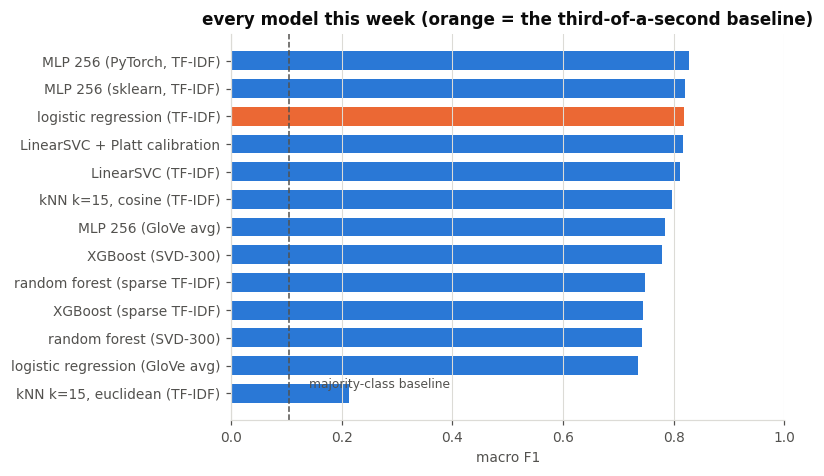

In [57]:
plot_df = board[board.model != "baseline: majority class"].sort_values("macro F1")
fig, ax = plt.subplots(figsize=(7.4, 4.4))
colors = [C_ORANGE if "logistic regression (TF-IDF)" == m else C_BLUE for m in plot_df.model]
ax.barh(plot_df.model, plot_df["macro F1"], color=colors, height=0.68)
ax.axvline(board.loc[board.model == "baseline: majority class", "macro F1"].iloc[0],
           color=INK_2, ls="--", lw=1)
ax.annotate("majority-class baseline", (0.14, 0.2), color=INK_2, fontsize=8)
ax.set(xlim=(0, 1.0), xlabel="macro F1",
       title="every model this week (orange = the third-of-a-second baseline)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Read the board with §5 in hand, because macro-F1 alone would pick the MLP and
that is not obviously the right answer:

| Criterion | What the board says |
|---|---|
| **Macro F1** | The PyTorch MLP leads at 0.8275, one point over logistic regression's 0.8177. |
| **Is that lead real?** | §1.3 and §6.2 both measured the noise floor at ±0.007. A one-point gap is 1.4 standard deviations. **Treat the top five rows as tied.** |
| **Cost** | `LinearSVC` and logistic regression fit in a fraction of a second. The MLPs cost one to two seconds; XGBoost on sparse features costs **about 14 s and finishes ninth of fourteen**. |
| **Calibration (§5.5)** | Platt-scaled `LinearSVC` has an ECE of 0.033, roughly a third of everything else, and clears 43% of the queue at a 0.90 gate against the random forest's 4.7%. |
| **Interpretability (§2.2)** | Only the linear models hand you a readable list of what each class looks like — which is how we found the model keying on two posters' surnames. |
| **Failure behaviour (§5.7)** | 54 all-zero rows cost kNN 57 points and the linear models nothing. |
| **Slice robustness (§5.6)** | Every model here is ~26 points worse on documents under 43 tokens. Nothing on this board fixes that. |

A defensible recommendation: **ship `CalibratedClassifierCV(LinearSVC())`** —
statistically tied for first on macro F1, three times better calibrated than
anything else, a tenth of a second to fit, and interpretable — with an
explicit
`insufficient_text` branch in front of it for the 3% of traffic that arrives
with no usable text after preprocessing.

Note what that recommendation is *not*. It is not the top row of the table. The
argument for it is cost, calibration, interpretability and failure mode, made
against a baseline with the noise floor quoted. That is what this week's
assignment asks you to write, and **"it had the highest accuracy" is not it** —
particularly when, as here, the highest accuracy is not distinguishable from
fourth.

---

## 7 — What to carry forward

**Where this week sits.** Movement 1 turned text into numbers. This was
Movement 2: numbers into predictions, using the ISM 6251 toolkit unchanged.
The algorithms needed no modification. What needed rethinking was everything
around them — leakage, metric choice, calibration, and reading your own errors.

Six things that are yours now:

1. **Fit the linear baseline first.** On sparse text it is often the answer —
   here it was statistically tied with the best of thirteen alternatives, at a
   tiny fraction of the cost — and it is always the number every other model
   has to beat while justifying itself.
2. **Everything stateful goes inside the `Pipeline`.** A step that touches `y`
   outside the split invented 38 points of accuracy out of coin flips (§1.1).
3. **Sparse high-dimensional features suit additive models, not axis-aligned
   splits.** XGBoost lost 7 points to a linear model while costing two orders
   of magnitude more. If you want trees, change the features (§3.3), not the
   hyperparameters.
4. **Pick the metric before you see the score.** Macro when the small class
   matters; PR over ROC under imbalance; and accuracy at a 0.5 threshold is
   almost never the thing you care about (§5.2, §5.4).
5. **`predict_proba` existing is not the same as it being a probability**, and
   `LinearSVC` does not have one at all (§2.3, §5.5).
6. **Error analysis is a scheduled activity.** Ours found a data defect that no
   metric flagged, no exception reported, and one model family failed
   catastrophically on (§5.7) — plus a model quietly keying on two posters'
   surnames (§2.2) and a whole class failing for a reason no feature could
   express (§5.8).

**The open problem.** §6.3 is the honest limit, and we measured it: word order
is worth 0.27 points to this classifier, because the features cannot represent
it. On topic classification that costs little — and it still cost us the
`alt.atheism` class, where the whole distinction is the stance taken toward a
vocabulary rather than the vocabulary itself. n-grams are a patch that runs out
at a window of three.

Next week we stop discarding order. Sequence models read a document left to
right and carry state, and the question the whole week turns on is whether the
result is worth the cost — measured against the baseline sitting at the top of
this notebook's scoreboard, which we will run on the same data again.